# Module 2 — Advanced Classification: Gradient Boosting

Classificazione del **Severity Impairment Index (`sii`, 4 classi)** sul dataset CMI con i metodi di
**Gradient Boosting** visti a lezione.

Il preprocessing (split, scaling, encoding) è **identico** a quello dei notebook di Logistic Regression, SVM e Neural
Networks, così i risultati dei classificatori del Modulo 2 sono confrontabili sullo stesso test set.

| Libreria | Classe | Caratteristiche (dalle slide) |
|---|---|---|
| scikit-learn | `GradientBoostingClassifier` | Gradient Boosting "classico": alberi di regressione sui pseudo-residui, shrinkage con il learning rate |
| scikit-learn | `HistGradientBoostingClassifier` | versione a istogrammi (solo nella baseline, è la stessa idea di LightGBM) |
| XGBoost | `XGBClassifier` | regolarizzazione (`lambda`), pruning con `gamma`, crescita *level-wise* |
| LightGBM | `LGBMClassifier` | istogrammi, crescita *leaf-wise* (parametro chiave `num_leaves`) |
| CatBoost | `CatBoostClassifier` | alberi simmetrici (stessa condizione di split per tutti i nodi di un livello) |

Random Forest, Bagging e AdaBoost **non** sono trattati qui: sono nel notebook *Ensemble Methods*.

**Struttura del notebook**
1. Setup
2. Preprocessing comune (identico a Logistic Regression, SVM e Neural Network)
3. Funzioni di valutazione
4. Baseline: le librerie con i parametri di default, con e senza pesi di classe
5. Numero di alberi, learning rate e overfitting
6. Tuning degli iperparametri (`RandomizedSearchCV`, F1-macro, 5-fold stratificata)
7. Analisi del tuning e scelta del modello finale (in cross-validation)
8. Valutazione finale sul test set
9. Feature importance (descrizione del modello)
10. Confronto con Logistic Regression, SVM e Neural Network
11. Sintesi per il report

> **Legenda.** I blocchi **📌 Report** indicano cosa riportare nel report (tabelle, grafici, frasi chiave).
> I numeri citati nei commenti vengono dal run di riferimento.

**Tempo di esecuzione**: circa 8-10 minuti su CPU (quasi tutto nelle quattro ricerche degli iperparametri, sezione 6).

## 1. Setup

In [1]:
%matplotlib inline

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed

import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, average_precision_score)

from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier

# !pip install xgboost lightgbm catboost
import xgboost, lightgbm, catboost
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

T_INIZIO = time.time()   # per misurare il tempo totale di esecuzione del notebook

print('scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__,
      '| lightgbm', lightgbm.__version__, '| catboost', catboost.__version__)

scikit-learn 1.7.2 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10


## 2. Preprocessing comune

Codice **identico** a quello dei notebook di Logistic Regression, SVM e Neural Network: stesso split 80/20 stratificato
(`random_state=42`), stesso `ColumnTransformer`, stessa cross-validation. In questo modo tutti i classificatori del
Modulo 2 sono valutati sullo stesso test set e i risultati sono confrontabili.

Due osservazioni specifiche per il Gradient Boosting:
- gli alberi sono invarianti alle trasformazioni monotone delle feature, quindi lo **`StandardScaler` non serve**: viene
  lasciato solo per coerenza con gli altri notebook (non cambia gli split trovati dagli alberi);
- il preprocessor è sempre inserito in una **`Pipeline`** con il modello, così viene fittato solo sul training di ogni
  fold (nessun data leakage).

**Sbilanciamento.** Non si usano tecniche di resampling (Modulo 1), ma i **pesi di classe a livello di algoritmo**, che
entrano nella griglia di tuning.

In [2]:
RANDOM_STATE = 42

df = pd.read_csv('cmi_internet_final.csv')
y = df['sii']
X = df.drop(columns=['id', 'sii'])

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CLASSI = [0, 1, 2, 3]

print('Dataset:', df.shape, '| feature numeriche:', len(num_cols), '| categoriche:', len(cat_cols))
print('Train:', X_train.shape, '| Test:', X_test.shape,
      '| feature dopo il preprocessing:', clone(preprocessor).fit(X_train).transform(X_train).shape[1])

distr = pd.DataFrame({'train': y_train.value_counts().sort_index(),
                      'test': y_test.value_counts().sort_index(),
                      'freq. train': y_train.value_counts(normalize=True).sort_index().round(3)})
distr

Dataset: (8460, 50) | feature numeriche: 38 | categoriche: 10
Train: (6768, 48) | Test: (1692, 48) | feature dopo il preprocessing: 68


,train,test,freq. train
sii,,,
0,4666,1167,0.689
1,1270,317,0.188
2,762,190,0.113
3,70,18,0.010


I pesi `'balanced'` di scikit-learn valgono $w_c = \dfrac{n}{k \cdot n_c}$ (n = esempi, k = classi, $n_c$ = esempi della
classe c): ogni classe pesa complessivamente allo stesso modo nella loss. Con una classe 3 all'1% il peso di un suo
esempio è circa 67 volte quello di un esempio della classe 0. Come negli altri notebook del Modulo 2, nel tuning i valori
provati per i pesi di classe sono due: `None` e `'balanced'`.

In [3]:
pesi_bal = compute_class_weight('balanced', classes=np.array(CLASSI), y=y_train)
pd.DataFrame({'peso balanced': pesi_bal}, index=pd.Index(CLASSI, name='classe')).round(3)

,peso balanced
classe,
0,0.363
1,1.332
2,2.220
3,24.171


## 3. Funzioni di valutazione

Le metriche riportate sono le stesse degli altri notebook del Modulo 2: `accuracy`, `balanced_acc`, `f1_macro`,
`roc_auc` (macro one-vs-rest) e la F1 di ogni classe. La metrica usata per il tuning e per scegliere i modelli è la
**F1-macro**: l'accuracy è fuorviante perché il classificatore che predice sempre la classe 0 ha accuracy 0.690.

In [4]:
def metriche(nome, modello, X_te=None, y_te=None, f1_cv=np.nan):
    # Riga di metriche sul test set (stesse colonne degli altri notebook del Modulo 2)
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    y_pred = modello.predict(X_te)
    y_proba = modello.predict_proba(X_te)
    f1_classi = f1_score(y_te, y_pred, average=None, labels=CLASSI, zero_division=0)
    riga = {'modello': nome,
            'f1_macro_cv': f1_cv,
            'accuracy': accuracy_score(y_te, y_pred),
            'balanced_acc': balanced_accuracy_score(y_te, y_pred),
            'f1_macro': f1_score(y_te, y_pred, average='macro', zero_division=0),
            'roc_auc': roc_auc_score(y_te, y_proba, multi_class='ovr', average='macro', labels=CLASSI)}
    for c, f in zip(CLASSI, f1_classi):
        riga[f'f1_{c}'] = f
    return riga


def grafici_modello(nome, modello, X_te=None, y_te=None):
    # Confusion matrix (conteggi e normalizzata per riga), curve ROC e Precision-Recall one-vs-rest
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    y_pred = modello.predict(X_te)
    y_proba = modello.predict_proba(X_te)
    y_bin = label_binarize(y_te, classes=CLASSI)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=CLASSI), display_labels=CLASSI).plot(
        ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'{nome}\nConfusion matrix (conteggi)')
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=CLASSI, normalize='true'), display_labels=CLASSI).plot(
        ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
    axes[1].set_title(f'{nome}\nConfusion matrix (normalizzata per riga = recall)')
    for ax in axes:
        ax.set_xlabel('classe predetta'); ax.set_ylabel('classe reale')
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for i, c in enumerate(CLASSI):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        axes[0].plot(fpr, tpr, lw=2, label=f'classe {c} (AUC = {auc(fpr, tpr):.3f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_proba[:, i])
        ap = average_precision_score(y_bin[:, i], y_proba[:, i])
        axes[1].plot(rec, prec, lw=2, label=f'classe {c} (AP = {ap:.3f}, freq. base = {y_bin[:, i].mean():.3f})')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'{nome}\nCurve ROC one-vs-rest'); axes[0].legend(loc='lower right')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].set_title(f'{nome}\nCurve Precision-Recall one-vs-rest'); axes[1].legend(loc='upper right')
    plt.tight_layout(); plt.show()

### Pesi di classe per i modelli che accettano solo `sample_weight`

`LGBMClassifier` (`class_weight`), `CatBoostClassifier` (`auto_class_weights`) e `HistGradientBoostingClassifier`
(`class_weight`) hanno un iperparametro per i pesi di classe. `GradientBoostingClassifier` e `XGBClassifier` invece
accettano solo i pesi per esempio (`sample_weight`) nel `fit`.

Per poter mettere i pesi **nella griglia di tuning** insieme agli altri iperparametri (e non aggiungerli a posteriori a
un modello già ottimizzato) si usa un piccolo wrapper: riceve uno stimatore e un parametro `class_weight`
(`None` o `'balanced'`), calcola i `sample_weight` **sul training di ogni fold** e li passa al `fit`.

In [5]:
class ConPesiDiClasse(ClassifierMixin, BaseEstimator):
    # Wrapper: aggiunge l'iperparametro `class_weight` a uno stimatore che accetta solo `sample_weight` nel fit

    def __init__(self, estimator=None, class_weight=None):
        self.estimator = estimator
        self.class_weight = class_weight          # None | 'balanced'

    def fit(self, X, y):
        sw = None
        if self.class_weight is not None:
            sw = compute_sample_weight('balanced', y)     # calcolati solo sui dati passati al fit (il training del fold)
        self.estimator_ = clone(self.estimator).fit(X, y, sample_weight=sw)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    @property
    def feature_importances_(self):
        return self.estimator_.feature_importances_


def etichetta_pesi(v):
    # Etichetta leggibile per il valore dei pesi di classe nelle tabelle dei risultati
    if v is None or (isinstance(v, float) and np.isnan(v)) or str(v) == 'None':
        return 'None'
    return {'Balanced': 'balanced'}.get(str(v), str(v))

## 4. Baseline: parametri di default, con e senza pesi di classe

Prima del tuning vengono valutate le librerie viste a lezione con i **parametri di default**, in due versioni: senza pesi e con
pesi `'balanced'`. La valutazione è fatta in **5-fold cross-validation sul training** (il test set non viene toccato).
Viene registrata anche la F1-macro sul training di ogni fold, per misurare l'overfitting.

Scelte fatte:
- `learning_rate` di default di ogni libreria (0.1 per scikit-learn e LightGBM, 0.3 per XGBoost). Nel notebook del
  laboratorio il professore usa `learning_rate=1.0`: l'effetto di questo parametro è analizzato nella sezione 5;
- CatBoost ha di default 1000 iterazioni: viene limitato a **300** per contenere i tempi (il learning rate viene scelto
  automaticamente dalla libreria in base al numero di iterazioni);
- ogni modello usa **1 thread** e la parallelizzazione avviene sui fold (`n_jobs=-1` nella CV): così i risultati sono
  riproducibili e non si creano più thread dei core disponibili.

In [6]:
def modelli_baseline(pesi):
    # Le 5 librerie con i parametri di default; pesi = True -> pesi di classe 'balanced'
    gbc = GradientBoostingClassifier(random_state=RANDOM_STATE)
    xgb = XGBClassifier(tree_method='hist', random_state=RANDOM_STATE, n_jobs=1)
    return {
        'GradientBoosting (sklearn)': ConPesiDiClasse(gbc, 'balanced' if pesi else None),
        'HistGradientBoosting (sklearn)': HistGradientBoostingClassifier(
            class_weight='balanced' if pesi else None, random_state=RANDOM_STATE),
        'XGBoost': ConPesiDiClasse(xgb, 'balanced' if pesi else None),
        'LightGBM': LGBMClassifier(class_weight='balanced' if pesi else None,
                                   random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
        'CatBoost (300 iter.)': CatBoostClassifier(iterations=300, auto_class_weights='Balanced' if pesi else 'None',
                                                   random_seed=RANDOM_STATE, thread_count=1, verbose=0,
                                                   allow_writing_files=False),
    }

t0 = time.time()
righe = []

# riferimento: Dummy (classe più frequente)
dummy = Pipeline([('prep', clone(preprocessor)), ('clf', DummyClassifier(strategy='most_frequent'))])
r = cross_validate(dummy, X_train, y_train, cv=cv, scoring=['f1_macro', 'balanced_accuracy', 'accuracy'],
                   return_train_score=True)
righe.append({'modello': 'Dummy (most frequent)', 'pesi': '-', 'f1_macro_cv': r['test_f1_macro'].mean(),
              'std': r['test_f1_macro'].std(), 'f1_macro_train': r['train_f1_macro'].mean(),
              'balanced_acc_cv': r['test_balanced_accuracy'].mean(), 'accuracy_cv': r['test_accuracy'].mean(),
              'tempo_s': 0.0})

for pesi in [False, True]:
    for nome, modello in modelli_baseline(pesi).items():
        t1 = time.time()
        pipe = Pipeline([('prep', clone(preprocessor)), ('clf', modello)])
        r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['f1_macro', 'balanced_accuracy', 'accuracy'],
                           return_train_score=True, n_jobs=-1)
        righe.append({'modello': nome, 'pesi': 'balanced' if pesi else 'None',
                      'f1_macro_cv': r['test_f1_macro'].mean(), 'std': r['test_f1_macro'].std(),
                      'f1_macro_train': r['train_f1_macro'].mean(),
                      'balanced_acc_cv': r['test_balanced_accuracy'].mean(),
                      'accuracy_cv': r['test_accuracy'].mean(), 'tempo_s': time.time() - t1})

baseline = pd.DataFrame(righe)
print(f'Tempo baseline: {time.time() - t0:.0f} s')
baseline.round(3)

Tempo baseline: 95 s


,modello,pesi,f1_macro_cv,std,f1_macro_train,balanced_acc_cv,accuracy_cv,tempo_s
0,Dummy (most frequent),-,0.204,0.000,0.204,0.250,0.689,0.000
1,GradientBoosting (sklearn),None,0.276,0.024,0.607,0.289,0.685,17.900
2,HistGradientBoosting (sklearn),None,0.293,0.007,0.988,0.294,0.680,8.108
3,XGBoost,None,0.277,0.010,0.995,0.282,0.671,5.050
4,LightGBM,None,0.281,0.013,0.971,0.287,0.684,5.004
5,CatBoost (300 iter.),None,0.298,0.012,0.884,0.297,0.681,17.854
6,GradientBoosting (sklearn),balanced,0.324,0.015,0.562,0.357,0.516,14.137
7,HistGradientBoosting (sklearn),balanced,0.323,0.008,0.986,0.322,0.628,5.027
8,XGBoost,balanced,0.317,0.006,0.996,0.312,0.632,2.165
9,LightGBM,balanced,0.333,0.016,0.966,0.335,0.624,2.081


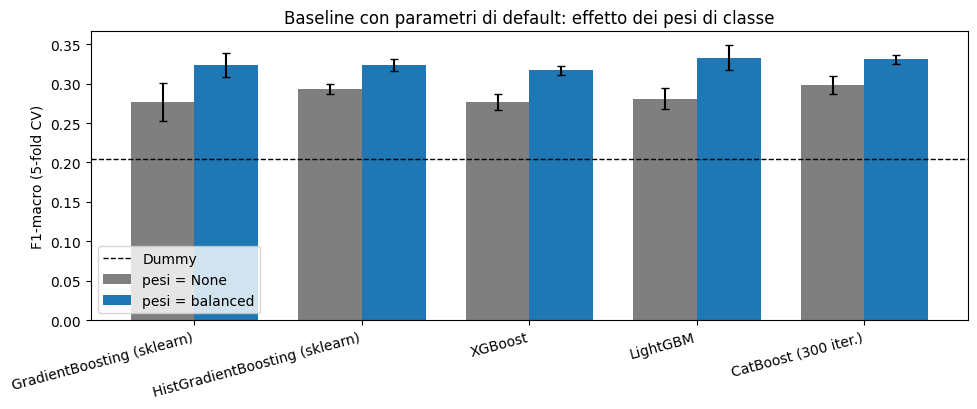

In [7]:
# F1-macro in CV (media ± dev. std sui 5 fold) con e senza pesi di classe
b = baseline[baseline['modello'] != 'Dummy (most frequent)']
nomi = list(b['modello'].unique())
x = np.arange(len(nomi))
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (pesi, colore) in enumerate([('None', 'tab:gray'), ('balanced', 'tab:blue')]):
    s = b[b['pesi'] == pesi].set_index('modello').loc[nomi]
    ax.bar(x + (i - 0.5) * 0.38, s['f1_macro_cv'], 0.38, yerr=s['std'], capsize=3, color=colore,
           label=f'pesi = {pesi}')
ax.axhline(baseline.loc[0, 'f1_macro_cv'], color='k', ls='--', lw=1, label='Dummy')
ax.set_xticks(x); ax.set_xticklabels(nomi, rotation=15, ha='right')
ax.set_ylabel('F1-macro (5-fold CV)'); ax.set_title('Baseline con parametri di default: effetto dei pesi di classe')
ax.legend(); plt.tight_layout(); plt.show()

**Commento.**
- **Senza pesi** tutte le librerie fanno poco meglio del Dummy: F1-macro in CV fra 0.276 e 0.298 (Dummy 0.204), con
  accuracy 0.67-0.685, cioè uguale o inferiore a quella del Dummy (0.689). Il modello migliore senza pesi è CatBoost (0.298).
- **Con i pesi `'balanced'`** la F1-macro sale in tutte le librerie di 0.03-0.05: da 0.317 (XGBoost) a 0.333 (LightGBM),
  con CatBoost a 0.331 e i due modelli di scikit-learn a 0.323-0.324. L'accuracy scende a 0.52-0.63 e la balanced accuracy sale
  da 0.28-0.30 a 0.31-0.36: i pesi spostano le predizioni dalla classe 0 verso le classi minoritarie.
- **Overfitting molto forte già con i default**: la F1-macro sul training è 0.97-1.00 per XGBoost, LightGBM e
  HistGradientBoosting e 0.88-0.92 per CatBoost, contro 0.28-0.33 in validazione. Solo il `GradientBoostingClassifier`
  (100 alberi di profondità 3) resta a 0.56-0.61. I modelli memorizzano il training ma questo non si traduce in una
  generalizzazione migliore: è quello che ci si aspetta con classi molto sovrapposte.
- Le deviazioni standard fra i fold (0.006-0.024) sono dello stesso ordine delle differenze fra le librerie: con i default
  non si può dire che una libreria sia migliore delle altre.
- Tempi (5 fold, su questa macchina): 14-18 s per `GradientBoostingClassifier`, 17-18 s per CatBoost, 2-8 s per le
  implementazioni a istogrammi.

**📌 Report**
- Tabella della baseline (F1-macro CV, F1-macro training, balanced accuracy, accuracy) con e senza pesi.
- Frase chiave: *anche nel Gradient Boosting i pesi di classe sono il fattore decisivo (+0.03-0.05 di F1-macro con i
  parametri di default); senza pesi i modelli hanno l'accuracy del Dummy.*
- Frase chiave: *con i parametri di default i modelli a istogrammi arrivano a F1-macro ≈ 1 sul training e ≈ 0.3 in
  validazione*: serve regolarizzare.

## 5. Numero di alberi, learning rate e overfitting

Nel Gradient Boosting ogni nuovo albero corregge gli errori (pseudo-residui) dei precedenti, e il suo contributo è
scalato dal **learning rate** $\nu$. Più alberi significa quindi un modello più complesso: a differenza del Bagging /
Random Forest, **aggiungere alberi può portare a overfitting**. I due parametri sono legati: un learning rate piccolo
richiede più alberi.

Per studiarlo viene addestrato XGBoost (`max_depth=3`, pesi `'balanced'`, 600 alberi) con cinque learning rate
(0.01, 0.05, 0.1, 0.3 e 1.0, il valore usato nel notebook del laboratorio) e, **per ognuno dei 5 fold** della CV,
vengono registrate al crescere del numero di alberi:
- la **log-loss pesata** su training e validation (è la loss che il boosting minimizza, e quella che userebbe
  l'**early stopping**). Poiché il modello è addestrato con i pesi di classe, anche la loss di validazione è pesata allo
  stesso modo (`sample_weight_eval_set`), altrimenti il criterio di arresto sarebbe dominato dalla classe 0;
- la **F1-macro** su training e validation (e l'accuracy di validation), calcolate ogni 10 alberi (`iteration_range`).

Si usa XGBoost perché è veloce e restituisce la loss a ogni iterazione; si usano i 5 fold (e non un solo validation set)
perché con ≈11 esempi della classe 3 in un singolo validation set le curve sarebbero troppo rumorose.

In [8]:
N_ALBERI = 600
PASSO = 10
LEARNING_RATES = [0.01, 0.05, 0.1, 0.3, 1.0]
passi = np.arange(PASSO, N_ALBERI + 1, PASSO)

def curve_fold(lr, idx_tr, idx_va):
    # Curve di apprendimento di XGBoost su un fold, per un dato learning rate
    prep = clone(preprocessor)
    Xa = prep.fit_transform(X_train.iloc[idx_tr]); ya = y_train.iloc[idx_tr]
    Xb = prep.transform(X_train.iloc[idx_va]);     yb = y_train.iloc[idx_va]
    wa = compute_sample_weight('balanced', ya)
    wb = compute_sample_weight('balanced', yb)      # pesi anche sulla validation
    m = XGBClassifier(n_estimators=N_ALBERI, learning_rate=lr, max_depth=3, tree_method='hist',
                      eval_metric='mlogloss', random_state=RANDOM_STATE, n_jobs=1)
    m.fit(Xa, ya, sample_weight=wa, eval_set=[(Xa, ya), (Xb, yb)], sample_weight_eval_set=[wa, wb], verbose=False)
    ev = m.evals_result()
    f1_tr = [f1_score(ya, m.predict(Xa, iteration_range=(0, int(k))), average='macro') for k in passi]
    pred_va = [m.predict(Xb, iteration_range=(0, int(k))) for k in passi]
    f1_va = [f1_score(yb, p, average='macro') for p in pred_va]
    acc_va = [accuracy_score(yb, p) for p in pred_va]
    return lr, np.array(ev['validation_0']['mlogloss']), np.array(ev['validation_1']['mlogloss']), \
           np.array(f1_tr), np.array(f1_va), np.array(acc_va)

t0 = time.time()
fold = list(cv.split(X_train, y_train))
ris = Parallel(n_jobs=-1)(delayed(curve_fold)(lr, tr, va) for lr in LEARNING_RATES for tr, va in fold)

curve = {}
for lr in LEARNING_RATES:
    r = [x for x in ris if x[0] == lr]
    curve[lr] = {'ll_tr': np.mean([x[1] for x in r], axis=0), 'll_va': np.mean([x[2] for x in r], axis=0),
                 'f1_tr': np.mean([x[3] for x in r], axis=0), 'f1_va': np.mean([x[4] for x in r], axis=0),
                 'f1_va_std': np.std([x[4] for x in r], axis=0), 'acc_va': np.mean([x[5] for x in r], axis=0)}
print(f'Tempo: {time.time() - t0:.0f} s')

Tempo: 45 s


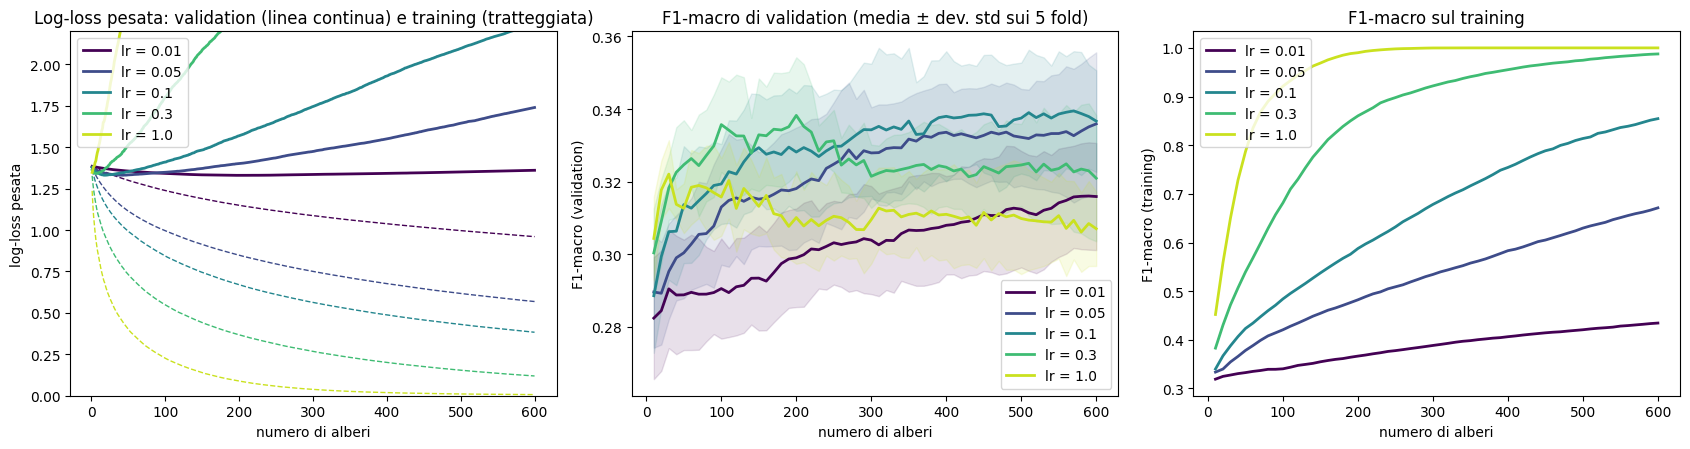

,learning_rate,alberi a log-loss val. minima,log-loss val. minima,F1 val. a quel punto,alberi a F1 val. massima,F1 val. massima,dev. std fold,F1 val. a 100 alberi,F1 val. a 300 alberi,F1 val. a 600 alberi,F1 train a 600 alberi,accuracy val. a 10 alberi,accuracy val. a 600 alberi
0,0.01,193,1.330,0.299,590,0.316,0.015,0.291,0.304,0.316,0.434,0.439,0.490
1,0.05,42,1.331,0.299,600,0.336,0.020,0.313,0.328,0.336,0.671,0.453,0.546
2,0.10,17,1.331,0.299,570,0.339,0.016,0.319,0.334,0.337,0.855,0.451,0.573
3,0.30,6,1.341,0.300,200,0.338,0.016,0.336,0.321,0.321,0.988,0.463,0.617
4,1.00,1,1.348,0.304,30,0.322,0.009,0.316,0.310,0.307,1.000,0.467,0.626


In [9]:
colori = plt.cm.viridis(np.linspace(0, 0.92, len(LEARNING_RATES)))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

for lr, col in zip(LEARNING_RATES, colori):
    c = curve[lr]
    axes[0].plot(np.arange(1, N_ALBERI + 1), c['ll_va'], color=col, lw=2, label=f'lr = {lr}')
    axes[0].plot(np.arange(1, N_ALBERI + 1), c['ll_tr'], color=col, lw=1, ls='--')
    axes[1].plot(passi, c['f1_va'], color=col, lw=2, label=f'lr = {lr}')
    axes[1].fill_between(passi, c['f1_va'] - c['f1_va_std'], c['f1_va'] + c['f1_va_std'], color=col, alpha=0.12)
    axes[2].plot(passi, c['f1_tr'], color=col, lw=2, label=f'lr = {lr}')

axes[0].set_ylim(0, 2.2); axes[0].set_xlabel('numero di alberi'); axes[0].set_ylabel('log-loss pesata')
axes[0].set_title('Log-loss pesata: validation (linea continua) e training (tratteggiata)'); axes[0].legend()
axes[1].set_xlabel('numero di alberi'); axes[1].set_ylabel('F1-macro (validation)')
axes[1].set_title('F1-macro di validation (media ± dev. std sui 5 fold)'); axes[1].legend()
axes[2].set_xlabel('numero di alberi'); axes[2].set_ylabel('F1-macro (training)')
axes[2].set_title('F1-macro sul training'); axes[2].legend()
plt.tight_layout(); plt.show()

# tabella riassuntiva
righe = []
for lr in LEARNING_RATES:
    c = curve[lr]
    n_es = int(np.argmin(c['ll_va'])) + 1                      # dove si fermerebbe l'early stopping (min. loss di validation)
    i_es = min(max(int(round(n_es / PASSO)) - 1, 0), len(passi) - 1)
    i_best = int(np.argmax(c['f1_va']))
    righe.append({'learning_rate': lr,
                  'alberi a log-loss val. minima': n_es,
                  'log-loss val. minima': c['ll_va'].min(),
                  'F1 val. a quel punto': c['f1_va'][i_es],
                  'alberi a F1 val. massima': int(passi[i_best]),
                  'F1 val. massima': c['f1_va'][i_best],
                  'dev. std fold': c['f1_va_std'][i_best],
                  'F1 val. a 100 alberi': c['f1_va'][100 // PASSO - 1],
                  'F1 val. a 300 alberi': c['f1_va'][300 // PASSO - 1],
                  f'F1 val. a {N_ALBERI} alberi': c['f1_va'][-1],
                  f'F1 train a {N_ALBERI} alberi': c['f1_tr'][-1],
                  'accuracy val. a 10 alberi': c['acc_va'][0],
                  f'accuracy val. a {N_ALBERI} alberi': c['acc_va'][-1]})
tab_curve = pd.DataFrame(righe)
tab_curve.round(3)

**Commento.**
- **Log-loss (grafico a sinistra).** La log-loss pesata sul training scende sempre, tanto più in fretta quanto più alto è
  il learning rate. Quella di validation ha invece il minimo dopo pochissimi alberi e poi **risale**: 193 alberi con
  lr 0.01, 42 con 0.05, 17 con 0.1, 6 con 0.3 e 1 solo albero con 1.0. Il valore minimo è circa 1.33-1.35 in tutti i casi,
  appena sotto a $\ln 4 \approx 1.386$, la log-loss di chi assegna 0.25 a ogni classe: in termini di probabilità il
  modello impara poco, e dopo poche iterazioni diventa troppo sicuro di sé su esempi che sbaglia.
- **F1-macro (grafico centrale).** La F1-macro di validation continua però a crescere ben oltre il minimo della log-loss.
  Con lr 0.1 passa da circa 0.30 al minimo della log-loss (17 alberi) a 0.319 (100 alberi), 0.334 (300) e 0.337 (600); con lr 0.05 arriva a 0.336 a 600
  alberi; con lr 0.01 è ancora in crescita a 600 alberi (0.316): 600 alberi non bastano. Con lr 0.3 il massimo (0.338) è a
  200 alberi e poi cala a 0.321; con **lr 1.0** il massimo è 0.322 a 30 alberi e poi scende a 0.307.
- Le curve di validation sono rumorose (dev. std fra i fold 0.015-0.020): i massimi con lr 0.05, 0.1 e 0.3
  (0.336-0.339) sono equivalenti. Quello che cambia è **dove** si raggiungono e cosa succede dopo: un learning rate più
  piccolo richiede più alberi ma poi resta stabile, uno più grande arriva prima e poi peggiora.
- **Training (grafico a destra).** A 600 alberi la F1-macro sul training è 0.43 (lr 0.01), 0.67 (0.05), 0.86 (0.1), 0.99
  (0.3) e 1.00 (1.0): la distanza fra training e validation cresce sempre, ma la F1-macro di validation non ne risente
  finché il learning rate è ≤ 0.1.
- **Più alberi = meno effetto dei pesi.** L'accuracy di validation sale con il numero di alberi (da 0.44-0.47 con 10
  alberi fino a 0.57 con lr 0.1 e 0.62-0.63 con lr 0.3 e 1.0 a 600 alberi): man mano che il modello si adatta al
  training, le predizioni tornano verso la classe maggioritaria.
- **Early stopping.** Fermarsi al minimo della log-loss di validation (anche pesata) darebbe modelli con F1-macro
  di circa 0.30, cioè 0.03-0.04 in meno di quanto si ottiene continuando ad aggiungere alberi. Il valore è approssimato:
  la F1-macro è calcolata ogni 10 alberi, quindi la colonna "F1 val. a quel punto" riporta la F1 al multiplo di 10 più
  vicino (20 alberi per lr 0.1, 10 alberi per lr 0.3 e 1.0). Sulla log-loss l'early stopping
  funziona come previsto, ma la log-loss qui non è un buon indicatore della F1-macro: per questo nel tuning il numero di
  alberi è un iperparametro della griglia, valutato direttamente con la F1-macro.

**📌 Report**
- Figura con le tre curve (log-loss, F1-macro di validation, F1-macro di training) e tabella riassuntiva per learning rate.
- Risposta alla domanda delle guidelines sull'effetto del **numero di modelli base**: a differenza degli ensemble basati
  sul bagging, nel boosting aggiungere alberi aumenta la complessità; la F1-macro cresce fino a 300-600 alberi con
  learning rate 0.05-0.1 e peggiora con learning rate alti.
- Frase chiave: *il learning rate 1.0 usato negli esempi di laboratorio porta a F1-macro = 1 sul training e al risultato
  peggiore in validazione a regime (0.307)*.
- Frase chiave: *log-loss di validation minima e F1-macro massima non coincidono: l'early stopping sulla loss fermerebbe
  il modello troppo presto (circa 0.30 contro 0.34)*.

## 6. Tuning degli iperparametri

Per ognuna delle quattro librerie viene fatta una ricerca con **`RandomizedSearchCV`**, `scoring='f1_macro'`, 5-fold
stratificata (la stessa `cv` degli altri notebook).

**Perché una ricerca casuale.** Le griglie hanno da 6 a 9 iperparametri: la griglia completa di XGBoost avrebbe più di
31 000 combinazioni. La ricerca casuale esplora lo spazio con un numero fissato di configurazioni: 40 per XGBoost e
30 per LightGBM (veloci), 12 per CatBoost e per il `GradientBoostingClassifier` di scikit-learn (lenti: il secondo non
usa istogrammi e costruisce un albero per classe a ogni iterazione). In tutto 94 configurazioni × 5 fold = 470 fit.

**Iperparametri comuni a tutte le ricerche**

| Parametro | Valori | Motivazione |
|---|---|---|
| pesi di classe | `None`, `balanced` | in LR, SVM e NN è stato il parametro decisivo; sono ottimizzati **insieme** agli altri |
| numero di alberi | 100 – 600 | dalla sezione 5: con learning rate 0.05-0.1 la F1-macro cresce fino a 300-600 alberi; con 0.3 il massimo è intorno a 200 |
| learning rate | 0.01 – 0.3 | 1.0 escluso (sezione 5); va ottimizzato insieme al numero di alberi |
| profondità / foglie | alberi piccoli (profondità 2-6) | le slide indicano alberi piccoli (8-32 foglie); con classi sovrapposte ci si aspetta che modelli semplici generalizzino meglio |
| `subsample` | 0.6 – 1.0 | *stochastic gradient boosting* (Friedman, 2002): ogni albero vede una frazione delle righe, riduce la varianza |

Il numero di alberi è nella griglia (e non scelto con l'early stopping dentro la ricerca) perché l'early stopping
richiederebbe un ulteriore validation set ritagliato da ogni fold, e nella sezione 5 si è visto che il minimo della
log-loss non coincide con il massimo della F1-macro.

In [10]:
ricerche = {}

def esegui_ricerca(nome, stimatore, griglia, n_iter):
    # RandomizedSearchCV su una pipeline (preprocessing + modello); stampa tempo e migliori configurazioni
    t0 = time.time()
    pipe = Pipeline([('prep', clone(preprocessor)), ('clf', stimatore)])
    rs = RandomizedSearchCV(pipe, griglia, n_iter=n_iter, scoring='f1_macro', cv=cv, n_jobs=-1,
                            random_state=RANDOM_STATE, return_train_score=True)
    rs.fit(X_train, y_train)
    ris = pd.DataFrame(rs.cv_results_)
    col_par = [c for c in ris.columns if c.startswith('param_')]
    tab = ris[col_par + ['mean_test_score', 'std_test_score', 'mean_train_score', 'mean_fit_time']].copy()
    tab.columns = [c.replace('param_clf__', '').replace('estimator__', '') for c in tab.columns]
    col_pesi = [c for c in tab.columns if 'class_weight' in c][0]
    tab = tab.rename(columns={col_pesi: 'pesi', 'mean_test_score': 'f1_cv', 'std_test_score': 'std',
                              'mean_train_score': 'f1_train', 'mean_fit_time': 'fit_s'})
    tab['pesi'] = tab['pesi'].map(etichetta_pesi)
    tab = tab.sort_values('f1_cv', ascending=False).reset_index(drop=True)
    ricerche[nome] = {'search': rs, 'tabella': tab}
    print(f'{nome}: {n_iter} configurazioni x 5 fold in {time.time() - t0:.0f} s')
    print(f'Migliore F1-macro CV = {rs.best_score_:.3f}')
    print('F1-macro CV per valore dei pesi (media | massimo | n. configurazioni):')
    print(tab.groupby('pesi')['f1_cv'].agg(['mean', 'max', 'count']).round(3).to_string())
    return tab

### 6.1 XGBoost

Oltre ai parametri comuni, per XGBoost vengono provati i parametri di **regolarizzazione** spiegati a lezione:
- `reg_lambda` (1, 5, 20): entra al denominatore del *similarity score* e del valore delle foglie, riduce il peso delle
  foglie con pochi esempi;
- `gamma` (0, 1, 5): soglia di **pruning**, un ramo viene tagliato se il suo *gain* è inferiore a `gamma`;
- `min_child_weight` (1, 5, 20): somma minima degli hessiani in una foglia (impedisce foglie con pochissimi esempi);
- `colsample_bytree` (0.5, 0.8, 1.0): frazione di feature usata da ogni albero;
- `max_depth` (2, 3, 4, 6): XGBoost cresce *level-wise*, quindi la complessità si controlla con la profondità
  (6 è il default).

`tree_method='hist'` (split approssimati su istogrammi) per la velocità.

In [11]:
griglia_xgb = {
    'clf__class_weight': [None, 'balanced'],
    'clf__estimator__n_estimators': [100, 200, 400, 600],
    'clf__estimator__learning_rate': [0.01, 0.03, 0.1, 0.3],
    'clf__estimator__max_depth': [2, 3, 4, 6],
    'clf__estimator__subsample': [0.6, 0.8, 1.0],
    'clf__estimator__colsample_bytree': [0.5, 0.8, 1.0],
    'clf__estimator__reg_lambda': [1, 5, 20],
    'clf__estimator__gamma': [0, 1, 5],
    'clf__estimator__min_child_weight': [1, 5, 20],
}
xgb_base = ConPesiDiClasse(XGBClassifier(tree_method='hist', importance_type='total_gain',
                                         random_state=RANDOM_STATE, n_jobs=1))
tab_xgb = esegui_ricerca('XGBoost', xgb_base, griglia_xgb, n_iter=40)
tab_xgb.head(8).round(3)

XGBoost: 40 configurazioni x 5 fold in 81 s
Migliore F1-macro CV = 0.343
F1-macro CV per valore dei pesi (media | massimo | n. configurazioni):
           mean    max  count
pesi                         
None      0.254  0.296     17
balanced  0.325  0.343     23


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,pesi,f1_cv,std,f1_train,fit_s
0,0.6,20,100,5,6,0.30,1,0.5,balanced,0.343,0.022,0.833,2.835
1,1.0,1,100,5,6,0.10,0,0.8,balanced,0.338,0.011,0.823,3.716
2,0.6,5,200,5,6,0.01,1,1.0,balanced,0.336,0.017,0.611,9.742
3,0.6,5,200,5,4,0.30,0,1.0,balanced,0.335,0.014,0.942,5.440
4,1.0,1,200,20,6,0.03,0,0.8,balanced,0.335,0.011,0.651,6.871
5,0.8,1,400,5,6,0.03,5,1.0,balanced,0.335,0.019,0.599,9.396
6,0.6,1,600,1,4,0.01,0,0.5,balanced,0.334,0.015,0.558,14.924
7,0.6,5,600,20,6,0.01,5,1.0,balanced,0.334,0.020,0.539,16.896


**Commento.**
- Migliore configurazione: F1-macro CV **0.343 ± 0.022** con pesi `balanced`, 100 alberi, `learning_rate=0.3`,
  `max_depth=6`, `min_child_weight=5`, `gamma=1`, `reg_lambda=20`, `colsample_bytree=0.5`, `subsample=0.6`. Rispetto al
  default con pesi `balanced` della baseline (0.317) il guadagno è di 0.026, ma la deviazione standard fra i fold è la più
  alta fra le prime otto configurazioni.
- **Pesi di classe**: media 0.254 senza pesi (17 configurazioni, massimo 0.296), 0.325 con `balanced` (23 configurazioni,
  massimo 0.343). Le prime otto configurazioni hanno tutte i pesi e nessuna configurazione senza pesi arriva a 0.30.
- **Complessità**: l'attesa che alberi poco profondi generalizzassero meglio non è confermata. Sei delle prime otto
  configurazioni hanno `max_depth=6` (le altre due 4), ma sempre insieme a qualcosa che limita il modello: `subsample` e
  `colsample_bytree` < 1, `reg_lambda` ≥ 5, `gamma` > 0 oppure un learning rate basso (0.01-0.03). La F1-macro sul
  training delle prime otto va da 0.54 a 0.94, contro lo 0.996 del default.
- Le prime otto configurazioni sono fra 0.334 e 0.343, con parametri molto diversi fra loro: la superficie è piatta.

**📌 Report**
- Tabella con le prime 5-8 configurazioni e la tabella media/massimo per valore dei pesi.
- Parametri provati e motivazione (tabella nel testo sopra); migliori: pesi di classe attivi, alberi anche profondi (6)
  purché con sottocampionamento di righe e colonne o regolarizzazione.

### 6.2 LightGBM

LightGBM cresce gli alberi *leaf-wise*: il parametro che controlla la complessità è **`num_leaves`** (4, 8, 16, 31;
31 è il default), affiancato da `max_depth` (-1 = nessun limite, 3, 6) come vincolo aggiuntivo. Gli altri parametri:
- `min_child_samples` (10, 20, 50, 100): numero minimo di esempi in una foglia. Con la crescita leaf-wise è il
  parametro principale contro l'overfitting; valori alti impediscono foglie costruite sui pochi esempi della classe 3;
- `reg_lambda` (0, 5, 20): regolarizzazione L2 sui valori delle foglie;
- `colsample_bytree` (0.5, 0.8, 1.0) e `subsample` (0.6, 0.8, 1.0; attivo con `subsample_freq=1`).

I pesi sono passati con l'iperparametro nativo `class_weight` (`None` o `'balanced'`). Resta il `boosting_type='gbdt'` di
default (non GOSS: con 6768 righe il campionamento sui gradienti non
serve per la velocità).

In [12]:
griglia_lgbm = {
    'clf__class_weight': [None, 'balanced'],
    'clf__n_estimators': [100, 200, 400, 600],
    'clf__learning_rate': [0.01, 0.03, 0.1, 0.3],
    'clf__num_leaves': [4, 8, 16, 31],
    'clf__max_depth': [-1, 3, 6],
    'clf__min_child_samples': [10, 20, 50, 100],
    'clf__subsample': [0.6, 0.8, 1.0],
    'clf__colsample_bytree': [0.5, 0.8, 1.0],
    'clf__reg_lambda': [0, 5, 20],
}
lgbm_base = LGBMClassifier(subsample_freq=1, importance_type='gain', random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
tab_lgbm = esegui_ricerca('LightGBM', lgbm_base, griglia_lgbm, n_iter=30)
tab_lgbm.head(8).round(3)

LightGBM: 30 configurazioni x 5 fold in 63 s
Migliore F1-macro CV = 0.341
F1-macro CV per valore dei pesi (media | massimo | n. configurazioni):
           mean    max  count
pesi                         
None      0.262  0.304     19
balanced  0.325  0.341     11


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree,pesi,f1_cv,std,f1_train,fit_s
0,1.0,0,16,100,10,6,0.10,1.0,balanced,0.341,0.023,0.822,2.082
1,0.8,0,16,400,50,6,0.03,1.0,balanced,0.341,0.020,0.861,8.412
2,1.0,20,16,100,50,6,0.10,0.5,balanced,0.334,0.016,0.695,1.754
3,0.8,20,16,200,10,6,0.01,1.0,balanced,0.326,0.015,0.485,4.714
4,1.0,5,8,200,20,6,0.30,1.0,balanced,0.325,0.020,0.936,2.971
5,0.6,5,8,600,50,6,0.30,0.5,balanced,0.322,0.025,0.996,6.836
6,0.8,20,31,400,100,6,0.30,1.0,balanced,0.321,0.006,1.000,8.646
7,0.6,20,4,200,50,3,0.03,1.0,balanced,0.320,0.016,0.400,2.063


**Commento.**
- Migliore configurazione: F1-macro CV **0.341 ± 0.023** con pesi `balanced`, 100 alberi, `learning_rate=0.1`,
  `num_leaves=16`, `max_depth=6`, `min_child_samples=10`, `colsample_bytree=1.0`, `subsample=1.0`, `reg_lambda=0`. La
  seconda ha lo stesso punteggio (0.341 ± 0.020) con 400 alberi, lr 0.03, `min_child_samples=50` e `subsample=0.8`:
  meno alberi con learning rate più alto o più alberi con learning rate più basso portano allo stesso risultato
  (sezione 5). Il default con pesi della baseline era a 0.333.
- **Pesi di classe**: media 0.262 senza pesi (19 configurazioni, massimo 0.304), 0.325 con `balanced` (11
  configurazioni, massimo 0.341). Le prime otto configurazioni hanno tutte i pesi.
- **Foglie e profondità**: le prime quattro configurazioni hanno `num_leaves=16` e sette delle prime otto `max_depth=6`.
  È un'indicazione, non una prova (con 11 configurazioni con i pesi i casi sono pochi). Per `min_child_samples` non
  emerge un effetto: cinque delle prime otto hanno un valore ≥ 50, ma metà dei valori in griglia è ≥ 50, quindi quattro
  sono attese anche per caso, e la configurazione migliore ha il valore più basso (10).
- **Learning rate alto**: le tre configurazioni con lr 0.3 fra le prime otto arrivano a F1-macro 0.94-1.00 sul training
  e si fermano a 0.321-0.325 in CV, circa 0.02 sotto le migliori (che sul training hanno 0.82-0.86).

**📌 Report**
- Tabella con le prime configurazioni e la tabella per valore dei pesi.
- Frase chiave: *in LightGBM 100 alberi con learning rate 0.1 e 400 alberi con learning rate 0.03 danno la stessa
  F1-macro in CV (0.341)*.

### 6.3 CatBoost

CatBoost usa **alberi simmetrici** (la stessa condizione di split per tutti i nodi di un livello): sono modelli più
vincolati, quindi i parametri da ottimizzare sono meno:
- `depth` (3, 4, 6; 6 è il default): un albero simmetrico di profondità d ha esattamente $2^d$ foglie;
- `l2_leaf_reg` (1, 3, 10, 30): regolarizzazione L2 sui valori delle foglie (3 è il default);
- `iterations` (200, 400) e `learning_rate` (0.03, 0.1, 0.3);
- `auto_class_weights`: `None`, `Balanced`.

CatBoost è la libreria più lenta su questo problema, quindi vengono provate solo 12 configurazioni e al massimo 400 iterazioni.
La sua caratteristica principale, l'*ordered target encoding* delle variabili categoriche, qui non viene sfruttata:
per usare lo stesso preprocessing degli altri classificatori le 10 variabili `Season` arrivano già in one-hot.

In [13]:
griglia_cat = {
    'clf__auto_class_weights': ['None', 'Balanced'],
    'clf__iterations': [200, 400],
    'clf__learning_rate': [0.03, 0.1, 0.3],
    'clf__depth': [3, 4, 6],
    'clf__l2_leaf_reg': [1, 3, 10, 30],
}
cat_base = CatBoostClassifier(random_seed=RANDOM_STATE, thread_count=1, verbose=0, allow_writing_files=False)
tab_cat = esegui_ricerca('CatBoost', cat_base, griglia_cat, n_iter=12)
tab_cat.round(3)

CatBoost: 12 configurazioni x 5 fold in 110 s
Migliore F1-macro CV = 0.336
F1-macro CV per valore dei pesi (media | massimo | n. configurazioni):
           mean    max  count
pesi                         
None      0.251  0.292      7
balanced  0.319  0.336      5


,learning_rate,l2_leaf_reg,iterations,depth,pesi,f1_cv,std,f1_train,fit_s
0,0.03,1,400,6,balanced,0.336,0.008,0.650,58.013
1,0.10,1,200,4,balanced,0.325,0.005,0.535,9.959
2,0.03,30,400,4,balanced,0.319,0.012,0.399,19.445
3,0.10,30,200,3,balanced,0.315,0.007,0.402,6.417
4,0.03,10,200,3,balanced,0.300,0.016,0.348,5.485
5,0.30,3,400,6,None,0.292,0.010,0.966,57.044
6,0.30,10,200,6,None,0.289,0.011,0.643,28.669
7,0.10,10,400,3,None,0.267,0.006,0.332,12.310
8,0.03,10,400,6,None,0.235,0.004,0.300,54.182
9,0.03,1,400,3,None,0.232,0.005,0.258,12.274


**Commento.**
- Migliore configurazione: F1-macro CV **0.336 ± 0.008** con pesi `Balanced`, 400 iterazioni, `learning_rate=0.03`,
  `depth=6`, `l2_leaf_reg=1`. Migliora di poco la baseline con pesi (0.331) ed è fra i punteggi più stabili fra i fold.
- **Pesi di classe**: media 0.251 senza pesi (7 configurazioni, massimo 0.292), 0.319 con `Balanced` (5 configurazioni,
  massimo 0.336). Tutte le configurazioni con i pesi (0.300-0.336) stanno sopra tutte quelle senza.
- **Senza pesi conta il learning rate**: con lr 0.3 si arriva a 0.289-0.292, con lr 0.03 si resta a 0.219-0.235, cioè
  vicino al Dummy. È lo stesso legame fra learning rate e numero di alberi visto nella sezione 5.
- **Con i pesi** la configurazione più profonda e meno regolarizzata (`depth=6`, `l2_leaf_reg=1`) è la migliore, quelle
  con `depth=3` o `l2_leaf_reg=30` stanno fra 0.300 e 0.319. Con sole 5 configurazioni con i pesi è un'indicazione.
- Con 12 configurazioni l'esplorazione è limitata: è una scelta fatta per i tempi (una configurazione con `depth=6` e
  400 iterazioni richiede 54-58 s per fit, contro 2-8 s di LightGBM).

**📌 Report**
- Tabella completa delle 12 configurazioni.
- Limite da dichiarare: ricerca ridotta per i tempi di calcolo; l'encoding delle categoriche di CatBoost non è stato usato
  per mantenere lo stesso preprocessing degli altri modelli.

### 6.4 GradientBoostingClassifier (scikit-learn)

È l'implementazione "classica" dell'algoritmo delle slide (alberi di regressione sui pseudo-residui, uno per classe a
ogni iterazione), senza istogrammi: è la più lenta, quindi 12 configurazioni e al massimo 400 alberi.
- `max_depth` (2, 3, 4; 3 è il default) e `min_samples_leaf` (1, 20, 50) controllano la complessità dei singoli alberi;
- `subsample` (0.6, 0.8, 1.0): con valori < 1 si ottiene lo *stochastic gradient boosting*;
- `max_features='sqrt'` fissato: ogni split valuta solo 8 feature su 68, riduce molto i tempi e decorrela gli alberi.

I pesi di classe sono passati con il wrapper `ConPesiDiClasse`.

In [14]:
griglia_gbc = {
    'clf__class_weight': [None, 'balanced'],
    'clf__estimator__n_estimators': [100, 200, 400],
    'clf__estimator__learning_rate': [0.01, 0.03, 0.1, 0.3],
    'clf__estimator__max_depth': [2, 3, 4],
    'clf__estimator__min_samples_leaf': [1, 20, 50],
    'clf__estimator__subsample': [0.6, 0.8, 1.0],
}
gbc_base = ConPesiDiClasse(GradientBoostingClassifier(max_features='sqrt', random_state=RANDOM_STATE))
tab_gbc = esegui_ricerca('GradientBoosting (sklearn)', gbc_base, griglia_gbc, n_iter=12)
tab_gbc.round(3)

GradientBoosting (sklearn): 12 configurazioni x 5 fold in 61 s
Migliore F1-macro CV = 0.342
F1-macro CV per valore dei pesi (media | massimo | n. configurazioni):
           mean    max  count
pesi                         
None      0.269  0.314      7
balanced  0.331  0.342      5


,subsample,n_estimators,min_samples_leaf,max_depth,learning_rate,pesi,f1_cv,std,f1_train,fit_s
0,0.8,400,20,3,0.03,balanced,0.342,0.010,0.542,25.641
1,1.0,100,20,3,0.30,balanced,0.334,0.016,0.690,6.923
2,0.6,400,50,2,0.03,balanced,0.329,0.012,0.429,16.649
3,1.0,200,20,4,0.30,balanced,0.326,0.010,0.957,18.567
4,1.0,400,50,2,0.30,balanced,0.323,0.014,0.765,20.810
5,0.8,400,1,3,0.30,None,0.314,0.012,0.895,18.787
6,0.8,200,1,4,0.10,None,0.296,0.012,0.836,16.989
7,0.6,400,20,4,0.10,None,0.291,0.013,0.908,23.781
8,1.0,100,20,3,0.30,None,0.288,0.012,0.711,3.912
9,0.8,100,50,2,0.10,None,0.248,0.007,0.338,4.724


**Commento.**
- Migliore configurazione: F1-macro CV **0.342 ± 0.010** con pesi `balanced`, 400 alberi, `learning_rate=0.03`,
  `max_depth=3`, `subsample=0.8`, `min_samples_leaf=20` (baseline con pesi: 0.324). È un modello poco adattato al
  training (F1-macro 0.542).
- **Pesi di classe**: media 0.269 senza pesi (7 configurazioni, massimo 0.314), 0.331 con `balanced` (5 configurazioni,
  massimo 0.342). Tutte le configurazioni con i pesi (0.323-0.342) stanno sopra tutte quelle senza.
- La configurazione senza pesi a 0.314 (400 alberi, lr 0.3, F1-macro 0.895 sul training) è la migliore senza pesi di
  tutto il notebook, ma resta quasi 0.03 sotto la migliore con i pesi.
- **Learning rate**: fra le configurazioni con i pesi, quelle con lr 0.3 e almeno 200 alberi (0.326 e 0.323) stanno sotto
  quella con lr 0.03 e 400 alberi (0.342). All'estremo opposto, la configurazione con lr 0.01 e 100 alberi (senza pesi)
  resta esattamente al livello del Dummy (0.204): il modello non ha ancora imparato nulla.
- L'implementazione "classica" raggiunge lo stesso livello delle librerie più recenti: su un dataset di 6768 righe i
  vantaggi di XGBoost e LightGBM sono nei **tempi** (nella baseline 2-5 s contro 14-18 s per la CV), non nella qualità.

**📌 Report**
- Tabella completa delle 12 configurazioni.
- Frase chiave: *XGBoost e LightGBM sono più veloci del Gradient Boosting classico, ma non più accurati su questo dataset*.

## 7. Analisi del tuning e scelta del modello finale

Le 94 configurazioni provate vengono messe insieme per rispondere a due domande:
1. **quanto contano i pesi di classe** rispetto agli altri iperparametri? (riga in alto: F1-macro in CV per valore dei pesi)
2. **quanto overfitting c'è**, e i modelli che si adattano di più al training generalizzano meglio? (riga in basso:
   F1-macro sul training contro F1-macro in CV; sulla diagonale tratteggiata i due valori coincidono)

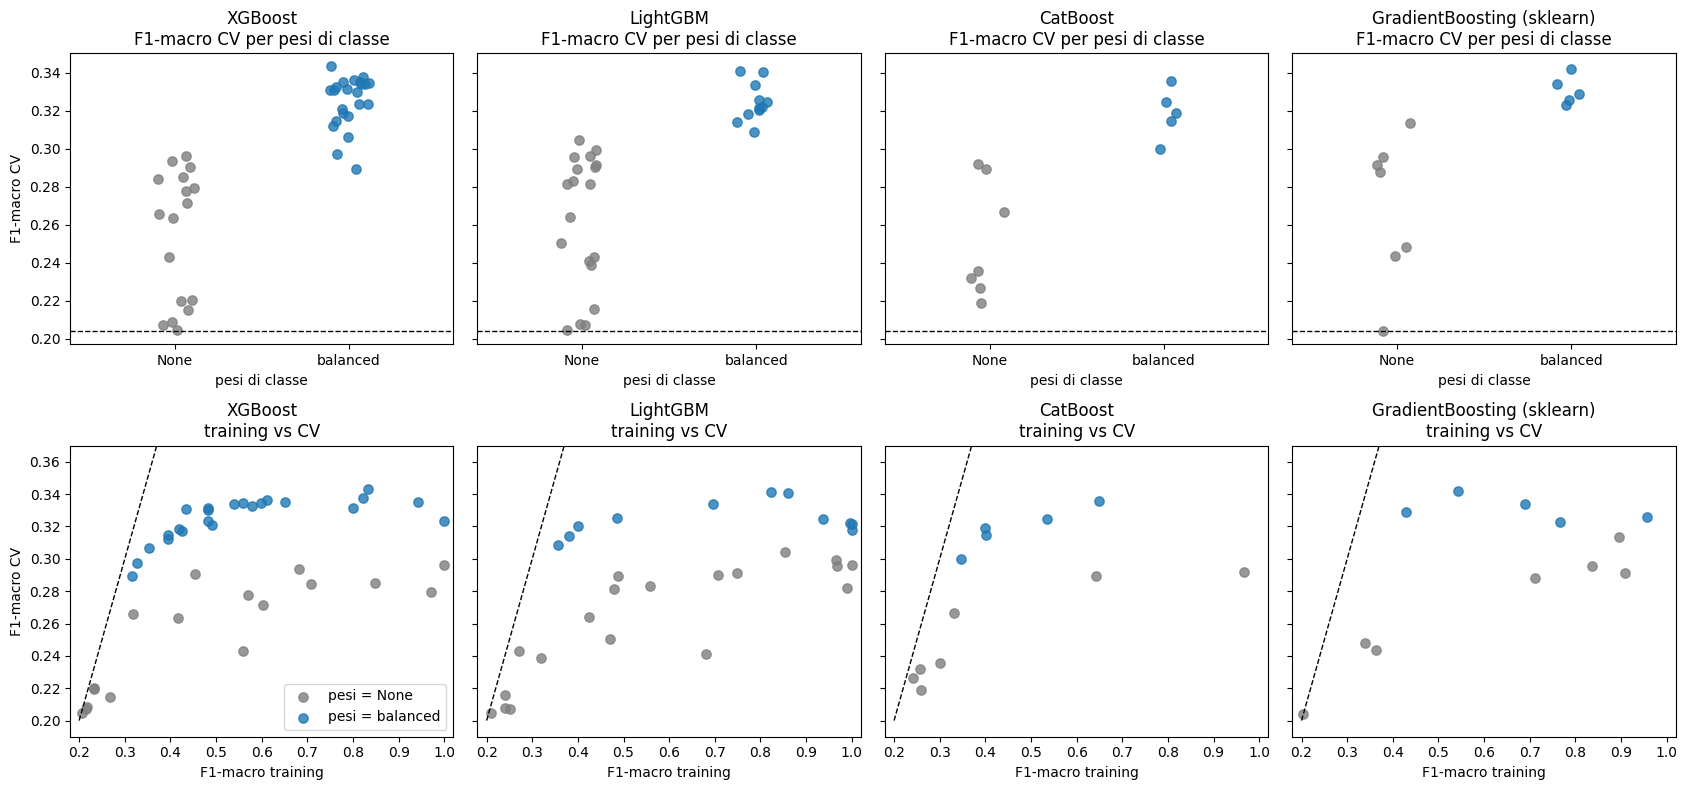

F1-macro CV media per pesi di classe e libreria:
pesi                         None  balanced
libreria                                   
CatBoost                    0.251     0.319
GradientBoosting (sklearn)  0.269     0.331
LightGBM                    0.262     0.325
XGBoost                     0.254     0.325

Correlazione (Spearman) fra F1 training e F1 CV, solo configurazioni con pesi balanced: 0.618
Numero di configurazioni con pesi e F1 CV >= 0.33: 18 su 44


In [15]:
ORDINE_PESI = ['None', 'balanced']
COL_PESI = {'None': 'tab:gray', 'balanced': 'tab:blue'}
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey='row')
for j, (nome, d) in enumerate(ricerche.items()):
    tab = d['tabella']
    for i, p in enumerate(ORDINE_PESI):
        s = tab[tab['pesi'] == p]
        axes[0, j].scatter(i + rng.uniform(-0.12, 0.12, len(s)), s['f1_cv'], color=COL_PESI[p], s=45, alpha=0.8)
        axes[1, j].scatter(s['f1_train'], s['f1_cv'], color=COL_PESI[p], s=45, alpha=0.8, label=f'pesi = {p}')
    axes[0, j].set_xticks(range(len(ORDINE_PESI))); axes[0, j].set_xlim(-0.6, len(ORDINE_PESI) - 0.4); axes[0, j].set_xticklabels(ORDINE_PESI)
    axes[0, j].set_title(f'{nome}\nF1-macro CV per pesi di classe'); axes[0, j].set_xlabel('pesi di classe')
    axes[0, j].axhline(0.204, color='k', ls='--', lw=1)
    axes[1, j].plot([0.2, 1], [0.2, 1], 'k--', lw=1)
    axes[1, j].set_xlim(0.18, 1.02); axes[1, j].set_ylim(0.19, 0.37)
    axes[1, j].set_title(f'{nome}\ntraining vs CV'); axes[1, j].set_xlabel('F1-macro training')
axes[0, 0].set_ylabel('F1-macro CV'); axes[1, 0].set_ylabel('F1-macro CV'); axes[1, 0].legend(loc='lower right')
plt.tight_layout(); plt.show()

tutte = pd.concat([d['tabella'].assign(libreria=n) for n, d in ricerche.items()], ignore_index=True)
tutte['gap_train_cv'] = tutte['f1_train'] - tutte['f1_cv']
print('F1-macro CV media per pesi di classe e libreria:')
print(tutte.pivot_table(index='libreria', columns='pesi', values='f1_cv', aggfunc='mean')[ORDINE_PESI].round(3).to_string())
print('\nCorrelazione (Spearman) fra F1 training e F1 CV, solo configurazioni con pesi balanced:',
      round(tutte[tutte['pesi'] != 'None'][['f1_train', 'f1_cv']].corr(method='spearman').iloc[0, 1], 3))
print('Numero di configurazioni con pesi e F1 CV >= 0.33:', int(((tutte['pesi'] != 'None') & (tutte['f1_cv'] >= 0.33)).sum()),
      'su', int((tutte['pesi'] != 'None').sum()))

**Commento.**
- **Pesi di classe (riga in alto).** In tutte e quattro le librerie le configurazioni senza pesi stanno sotto quelle con i
  pesi. F1-macro CV media senza pesi / con pesi `balanced`: XGBoost 0.254 / 0.325, LightGBM 0.262 / 0.325,
  GradientBoosting 0.269 / 0.331, CatBoost 0.251 / 0.319. In CatBoost e GradientBoosting non c'è alcuna sovrapposizione;
  in XGBoost e LightGBM solo le peggiori configurazioni con i pesi (0.29-0.31) scendono al livello delle migliori senza.
  La migliore delle 50 configurazioni senza pesi (0.314, GradientBoosting) resta 0.02-0.03 sotto le migliori con i pesi:
  nessuna combinazione degli altri iperparametri compensa l'assenza dei pesi.
- **Training contro CV (riga in basso).** Tutti i punti sono a destra della diagonale: l'overfitting è presente in ogni
  configurazione utile. Fra le 44 configurazioni con i pesi, la F1-macro in CV sale finché quella sul training arriva a
  circa 0.5-0.6 e poi **si appiattisce fra 0.32 e 0.34**: adattarsi di più al training (fino a 1.0) non aiuta. La
  correlazione di Spearman fra F1 sul training e F1 in CV è 0.62, e viene soprattutto dalle configurazioni poco adattate
  (training sotto 0.5), che sono anche le più basse in CV.
- **Superficie piatta.** 18 configurazioni con i pesi su 44 hanno F1-macro CV ≥ 0.33, con librerie e iperparametri molto
  diversi. Il limite intorno a 0.34 non dipende dalla libreria né dalla configurazione: è nei dati.

**📌 Report**
- Figura 2×4 (o solo la riga in alto, se lo spazio è poco) e tabella delle medie per pesi e libreria.
- Frase chiave: *i pesi di classe sono l'iperparametro più importante anche nel Gradient Boosting; una volta attivati,
  il 40% delle configurazioni provate ha F1-macro CV ≥ 0.33*.
- Frase chiave: *oltre F1-macro ≈ 0.6 sul training, adattarsi di più ai dati non migliora la validazione*.

### 7.1 Riepilogo dei modelli ottimizzati e scelta del modello finale

Per ogni libreria si prende la configurazione con la F1-macro più alta nella ricerca. Prima di scegliere fra le quattro
c'è però un problema da considerare: il punteggio della migliore configurazione su 12-40 provate **sugli stessi 5 fold**
è una stima ottimistica (è il massimo di tante stime rumorose), e le deviazioni standard fra i fold (0.008-0.023) sono
dello stesso ordine delle differenze fra le librerie.

Per questo le quattro configurazioni finaliste vengono rivalutate con una **cross-validation ripetuta** (5 fold × 3
ripetizioni) e come **modello finale** viene scelto quello con la F1-macro media più alta. Poiché `cv_rip` usa lo stesso
`random_state=42` della `cv`, la **prima ripetizione coincide con i 5 fold della ricerca** (`rip_1` è uguale a
`f1_macro_cv`): i fold davvero nuovi sono i 10 delle ripetizioni 2 e 3. La scelta resta fatta **solo sul training**,
senza guardare il test set. Nella tabella `f1_macro_cv` è il punteggio della ricerca (5 fold, confrontabile con gli
altri notebook) e `f1_macro_cv_rip` quello della CV ripetuta.

**Differenza rispetto agli altri notebook.** In LR, SVM e NN il modello finale è scelto direttamente sul `best_score_`
della 5-fold; qui la CV ripetuta è un controllo in più. Nel confronto finale (sezione 10) la colonna usata è comunque
`f1_macro_cv` a 5 fold, quindi i numeri sono omogenei con quelli degli altri notebook.

In [16]:
t0 = time.time()
cv_rip = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

righe = []
for nome, d in ricerche.items():
    rs, t = d['search'], d['tabella']
    par = {k.replace('clf__', '').replace('estimator__', ''): (etichetta_pesi(v) if 'class_weight' in k else v)
           for k, v in rs.best_params_.items()}
    s = cross_validate(clone(rs.best_estimator_), X_train, y_train, cv=cv_rip, scoring='f1_macro', n_jobs=-1)['test_score']
    righe.append({'modello': nome, 'f1_macro_cv': t.loc[0, 'f1_cv'], 'std': t.loc[0, 'std'],
                  'f1_macro_cv_rip': s.mean(), 'std_rip': s.std(),
                  'rip_1': s[:5].mean(), 'rip_2': s[5:10].mean(), 'rip_3': s[10:].mean(),
                  'f1_macro_train': t.loc[0, 'f1_train'], 'fit_s': t.loc[0, 'fit_s'], 'iperparametri': par})
riepilogo_cv = pd.DataFrame(righe).sort_values('f1_macro_cv_rip', ascending=False).reset_index(drop=True)

NOME_FINALE = riepilogo_cv.loc[0, 'modello']
modello_finale = ricerche[NOME_FINALE]['search'].best_estimator_
print(f'Tempo CV ripetuta: {time.time() - t0:.0f} s')
print('Modello finale scelto con la CV ripetuta:', NOME_FINALE)
for _, r in riepilogo_cv.iterrows():
    print(f"\n{r['modello']}: F1-macro CV ripetuta = {r['f1_macro_cv_rip']:.3f} ± {r['std_rip']:.3f} "
          f"(ricerca: {r['f1_macro_cv']:.3f} ± {r['std']:.3f})\n   {r['iperparametri']}")
riepilogo_cv.drop(columns='iperparametri').round(3)

Tempo CV ripetuta: 48 s
Modello finale scelto con la CV ripetuta: LightGBM

LightGBM: F1-macro CV ripetuta = 0.340 ± 0.017 (ricerca: 0.341 ± 0.023)
   {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 16, 'n_estimators': 100, 'min_child_samples': 10, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0, 'class_weight': 'balanced'}

GradientBoosting (sklearn): F1-macro CV ripetuta = 0.337 ± 0.010 (ricerca: 0.342 ± 0.010)
   {'subsample': 0.8, 'n_estimators': 400, 'min_samples_leaf': 20, 'max_depth': 3, 'learning_rate': 0.03, 'class_weight': 'balanced'}

CatBoost: F1-macro CV ripetuta = 0.334 ± 0.007 (ricerca: 0.336 ± 0.008)
   {'learning_rate': 0.03, 'l2_leaf_reg': 1, 'iterations': 400, 'depth': 6, 'auto_class_weights': 'balanced'}

XGBoost: F1-macro CV ripetuta = 0.331 ± 0.018 (ricerca: 0.343 ± 0.022)
   {'subsample': 0.6, 'reg_lambda': 20, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.3, 'gamma': 1, 'colsample_bytree': 0.5, 'class_weight': 'ba

,modello,f1_macro_cv,std,f1_macro_cv_rip,std_rip,rip_1,rip_2,rip_3,f1_macro_train,fit_s
0,LightGBM,0.341,0.023,0.340,0.017,0.341,0.339,0.339,0.822,2.082
1,GradientBoosting (sklearn),0.342,0.010,0.337,0.010,0.342,0.335,0.334,0.542,25.641
2,CatBoost,0.336,0.008,0.334,0.007,0.336,0.330,0.335,0.650,58.013
3,XGBoost,0.343,0.022,0.331,0.018,0.343,0.328,0.323,0.833,2.835


**Commento.**
- Nella ricerca i quattro migliori modelli erano in 0.007 di F1-macro: XGBoost 0.343, GradientBoosting 0.342,
  LightGBM 0.341, CatBoost 0.336.
- Con la **CV ripetuta** l'ordine cambia: **LightGBM 0.340 ± 0.017**, GradientBoosting 0.337 ± 0.010, CatBoost
  0.334 ± 0.007, XGBoost 0.331 ± 0.018. XGBoost passa dal primo all'ultimo posto: il suo punteggio scende di 0.012
  (0.343 / 0.328 / 0.323 nelle tre ripetizioni), quindi lo 0.343 della ricerca era in parte un risultato fortunato sui 5
  fold usati per il tuning. Gli altri tre modelli scendono al massimo di 0.005; LightGBM è il più costante
  (0.341 / 0.339 / 0.339).
- La prima ripetizione usa gli stessi 5 fold della ricerca (`rip_1` coincide con `f1_macro_cv` per tutti e quattro i
  modelli), quindi i fold nuovi sono 10 e non 15. Sulle sole ripetizioni 2 e 3 l'ordine è lo stesso: LightGBM 0.339,
  GradientBoosting circa 0.335, CatBoost circa 0.333, XGBoost circa 0.326.
- Il **modello finale** è **LightGBM** (`class_weight='balanced'`, 100 alberi, `learning_rate=0.1`, `num_leaves=16`,
  `max_depth=6`, `min_child_samples=10`, `colsample_bytree=1.0`, `subsample=1.0`, `reg_lambda=0`).
- Va detto con prudenza: la distanza fra LightGBM e gli altri (0.003-0.009) è inferiore alla deviazione standard fra i
  fold. I quattro modelli sono **equivalenti**; LightGBM è scelto perché ha la media più alta nella CV ripetuta ed è anche
  il più veloce (circa 2 s per fit, contro 26 di GradientBoosting e 58 di CatBoost).
- **Qui il criterio di scelta conta.** Con il criterio degli altri notebook (`best_score_` della 5-fold) il modello
  finale sarebbe stato XGBoost (0.343 contro 0.341 di LightGBM). Sul test i due modelli sono comunque quasi uguali
  (sezione 8), quindi il confronto con gli altri classificatori non cambierebbe.

**📌 Report**
- Tabella di riepilogo (F1-macro della ricerca, F1-macro della CV ripetuta, iperparametri migliori per libreria).
- Frase chiave: *il punteggio migliore di una ricerca su decine di configurazioni è ottimistico: rivalutato con una CV
  ripetuta (3×5, di cui 10 fold diversi da quelli della ricerca), XGBoost passa dal primo all'ultimo posto*.
- Da dichiarare: negli altri notebook il modello finale è scelto sul `best_score_` della 5-fold; qui quel criterio
  avrebbe scelto XGBoost invece di LightGBM.
- Scrivere "LightGBM ha la F1-macro più alta nella CV ripetuta", non "LightGBM è il migliore".

## 8. Valutazione finale sul test set

Solo ora viene usato il test set (1692 righe, mai viste durante baseline, analisi e tuning). I quattro modelli ottimizzati
sono riaddestrati su tutto il training (`refit=True` della ricerca) e valutati con le stesse colonne degli altri
notebook. Il test serve per **stimare** le prestazioni, non per scegliere: il modello finale resta quello scelto in CV.
Sono riportati tutti e quattro i modelli per mostrare quanto varia il risultato sul test fra modelli equivalenti in CV.

In [17]:
dummy_fit = Pipeline([('prep', clone(preprocessor)),
                      ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
righe = [metriche('Dummy (most frequent)', dummy_fit)]
for _, r in riepilogo_cv.iterrows():
    righe.append(metriche(r['modello'], ricerche[r['modello']]['search'].best_estimator_, f1_cv=r['f1_macro_cv']))
risultati_test = pd.DataFrame(righe)
risultati_test.insert(2, 'f1_macro_cv_rip', risultati_test['modello'].map(riepilogo_cv.set_index('modello')['f1_macro_cv_rip']))
risultati_test.round(3)

,modello,f1_macro_cv,f1_macro_cv_rip,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
0,Dummy (most frequent),NaN,NaN,0.690,0.250,0.204,0.500,0.816,0.000,0.000,0.000
1,LightGBM,0.341,0.340,0.569,0.344,0.328,0.701,0.732,0.294,0.287,0.000
2,GradientBoosting (sklearn),0.342,0.337,0.518,0.383,0.337,0.698,0.671,0.307,0.328,0.040
3,CatBoost,0.336,0.334,0.544,0.387,0.345,0.705,0.703,0.269,0.346,0.061
4,XGBoost,0.343,0.331,0.566,0.338,0.325,0.678,0.728,0.276,0.296,0.000


**Commento.**
- **Modello finale (LightGBM)**: F1-macro **0.328** sul test, contro 0.340 nella CV ripetuta (0.012 in meno, entro la
  deviazione standard fra i fold di 0.017), balanced accuracy 0.344, ROC AUC 0.701, accuracy 0.569. F1 per classe:
  0.732 / 0.294 / 0.287 / **0.000**.
- **Gli altri tre modelli**: CatBoost 0.345, GradientBoosting 0.337, XGBoost 0.325. I quattro modelli stanno in 0.009
  in CV (0.331-0.340) e in 0.020 sul test (0.325-0.345), con un ordine diverso: il modello scelto in CV non è quello con
  il valore più alto sul test. Non autorizza a dire che CatBoost sia il modello migliore: sarebbe scegliere sul test, e
  differenze di 0.01-0.02 su un test set con 18 esempi nella classe 3 non sono significative.
- **Due comportamenti diversi.** CatBoost e GradientBoosting hanno balanced accuracy più alta (0.387 e 0.383) e accuracy
  più bassa (0.544 e 0.518); LightGBM e XGBoost il contrario (balanced accuracy 0.344 e 0.338, accuracy 0.569 e 0.566).
  I primi due sono anche i modelli meno adattati al training (F1-macro 0.65 e 0.54, contro 0.82 e 0.83): è coerente con
  quanto visto nella sezione 5, dove adattarsi di più al training riporta le predizioni verso la classe 0.
- **Classe 3**: F1 = 0 per LightGBM e XGBoost, 0.040 per GradientBoosting e 0.061 per CatBoost.
- **ROC AUC** fra 0.678 (XGBoost) e 0.705 (CatBoost): le probabilità contengono informazione, ma il livello resta
  modesto e simile fra i modelli.

**📌 Report**
- Tabella dei risultati sul test (tutte le colonne) per Dummy e i quattro modelli.
- Frase chiave: *accuracy e F1-macro vanno in direzioni opposte anche qui: i due modelli con l'accuracy più alta
  (LightGBM 0.569 e XGBoost 0.566) hanno la F1-macro più bassa (0.328 e 0.325)*.
- Frase chiave: *sul test i quattro modelli variano fra 0.325 e 0.345 pur essendo equivalenti in CV: con 18 esempi nella
  classe 3 il test set non permette di ordinarli*.

Modello finale: LightGBM

              precision    recall  f1-score   support

           0      0.797     0.676     0.732      1167
           1      0.271     0.322     0.294       317
           2      0.232     0.379     0.287       190
           3      0.000     0.000     0.000        18

    accuracy                          0.569      1692
   macro avg      0.325     0.344     0.328      1692
weighted avg      0.626     0.569     0.592      1692



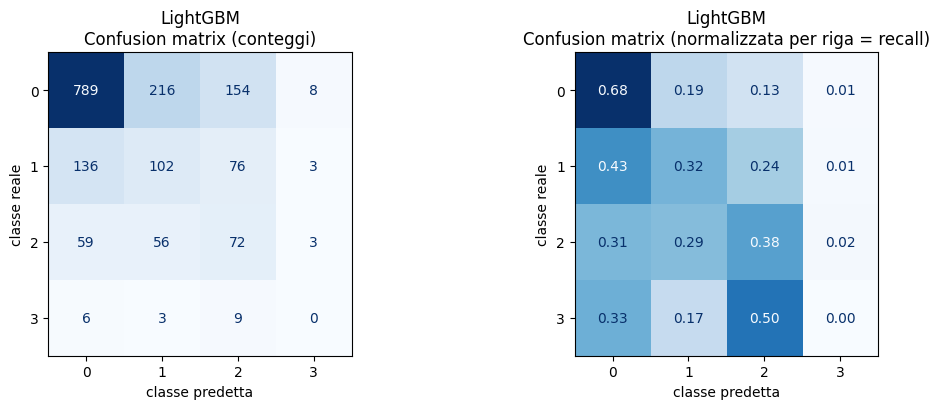

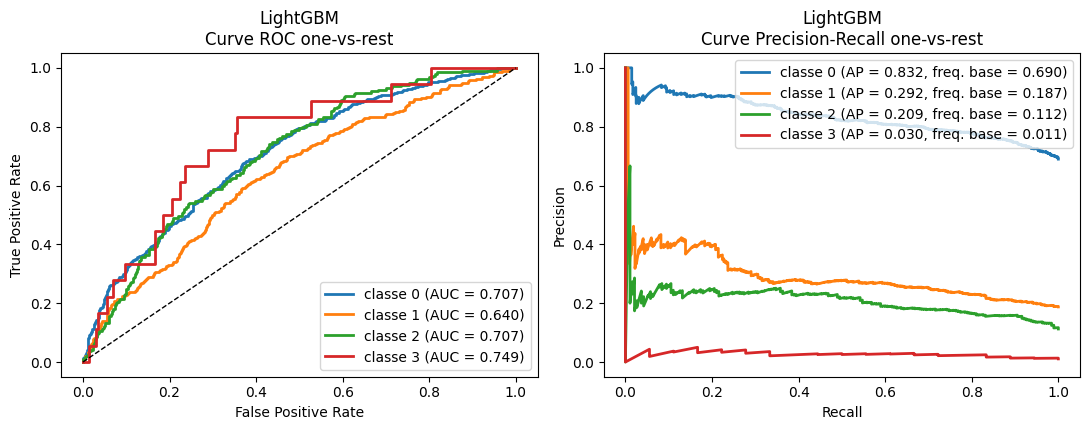

In [18]:
print(f'Modello finale: {NOME_FINALE}\n')
y_pred_finale = modello_finale.predict(X_test)
print(classification_report(y_test, y_pred_finale, digits=3, zero_division=0))
grafici_modello(NOME_FINALE, modello_finale)

**Commento.**
- **Classe 0**: precision 0.797, recall 0.676. 789 esempi su 1167 corretti; gli altri sono predetti soprattutto come
  classe 1 (216) e 2 (154): è il costo dei pesi di classe.
- **Classe 1 ("Mild")**: precision 0.271, recall 0.322 (102 su 317). Il 43% dei casi è predetto come classe 0 e il 24% come
  classe 2: è la classe "in mezzo" e ha la ROC AUC più bassa (0.640).
- **Classe 2**: precision 0.232, recall 0.379 (72 su 190), ROC AUC 0.707.
- **Classe 3**: **nessuno dei 18 casi è individuato** (9 predetti come classe 2, 6 come 0, 3 come 1) e le 14 predizioni di
  classe 3 fatte dal modello sono tutte sbagliate. La ROC AUC della classe 3 è però la più alta (0.749): i casi gravi
  ricevono in media una probabilità più alta degli altri, ma non abbastanza da diventare la classe predetta. L'average
  precision è 0.030 contro una frequenza base di 0.011.
- Gli errori sono per lo più fra **classi vicine** (la classe 3 è confusa soprattutto con la 2), coerentemente con la
  natura ordinale del target.
- Nelle curve Precision-Recall tutte le classi sono sopra la propria frequenza base, ma di poco per le classi 1 e 2
  (AP 0.292 e 0.209 contro 0.187 e 0.112).

**📌 Report**
- `classification_report`, confusion matrix normalizzata, curve ROC e Precision-Recall del modello finale.
- Risposta alla domanda delle guidelines sulla **classe che va male in tutti i classificatori**: è la classe 3 (1% dei
  dati, 70 esempi nel training e 18 nel test), con F1 = 0 anche per il modello finale del Gradient Boosting.
- Frase chiave: *gli errori avvengono soprattutto fra classi adiacenti*.

## 9. Feature importance

Come descrizione del modello (non come analisi di explainability, che è una parte separata del progetto) vengono riportate le
*feature importance* interne dei quattro modelli ottimizzati. Per renderle confrontabili si usa in tutte le librerie una
misura del **contributo totale** della feature: riduzione totale dell'impurità (scikit-learn), *gain* totale degli split
in cui la feature è usata (XGBoost con `importance_type='total_gain'`, LightGBM con `importance_type='gain'`),
variazione della predizione (CatBoost, `PredictionValuesChange`). Sono normalizzate a somma 1 e il confronto riguarda soprattutto
l'**ordine**. (Il default di XGBoost è invece il *gain medio per split*, che premia le feature usate in pochi split e non
è confrontabile con le altre librerie.)
Le colonne one-hot di ogni variabile `Season` sono sommate, così l'importanza è riferita alle 48 variabili originali.

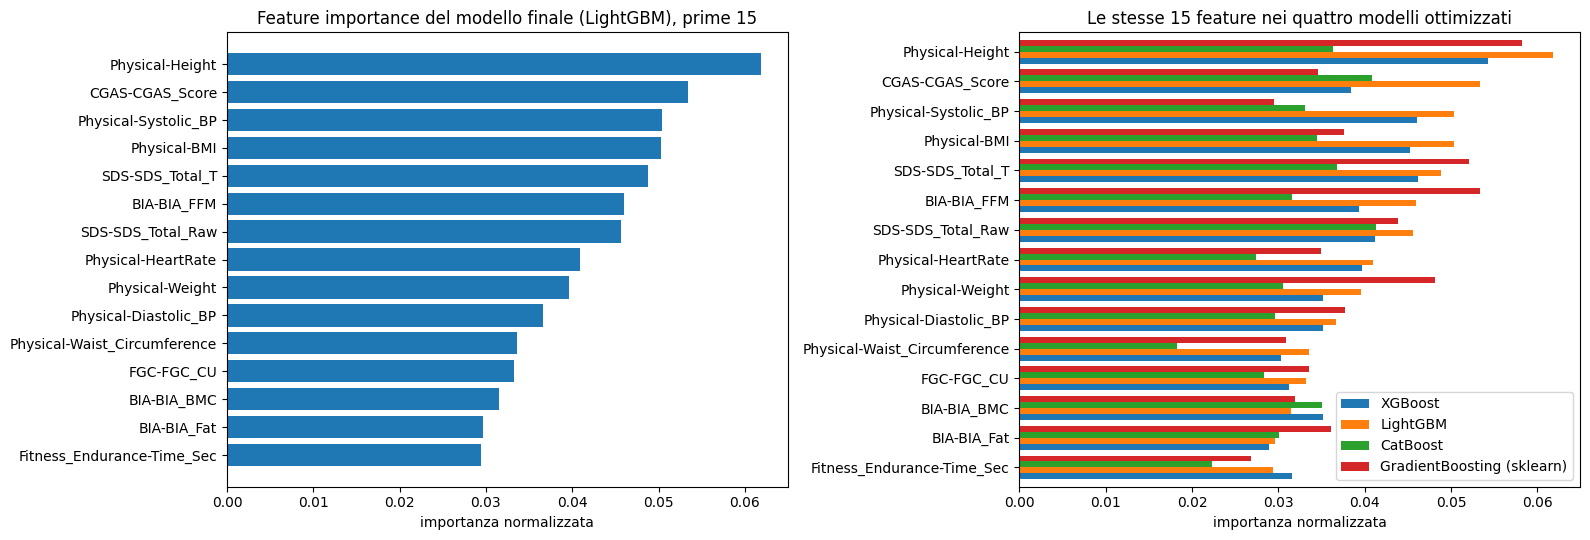

Importanza complessiva delle 10 variabili Season: {'XGBoost': 0.088, 'LightGBM': 0.079, 'CatBoost': 0.125, 'GradientBoosting (sklearn)': 0.084}
Importanza cumulata delle prime 10 feature: {'XGBoost': 0.43, 'LightGBM': 0.474, 'CatBoost': 0.369, 'GradientBoosting (sklearn)': 0.452}

Correlazione di Spearman fra gli ordinamenti delle feature:
                            XGBoost  LightGBM  CatBoost  GradientBoosting (sklearn)
XGBoost                        1.00      0.97      0.88                        0.96
LightGBM                       0.97      1.00      0.88                        0.96
CatBoost                       0.88      0.88      1.00                        0.87
GradientBoosting (sklearn)     0.96      0.96      0.87                        1.00


,XGBoost,LightGBM,CatBoost,GradientBoosting (sklearn),media
Physical-Height,0.054,0.062,0.036,0.058,0.053
CGAS-CGAS_Score,0.038,0.053,0.041,0.035,0.042
Physical-Systolic_BP,0.046,0.050,0.033,0.030,0.040
Physical-BMI,0.045,0.050,0.034,0.038,0.042
SDS-SDS_Total_T,0.046,0.049,0.037,0.052,0.046
BIA-BIA_FFM,0.039,0.046,0.032,0.053,0.043
SDS-SDS_Total_Raw,0.041,0.046,0.041,0.044,0.043
Physical-HeartRate,0.040,0.041,0.027,0.035,0.036
Physical-Weight,0.035,0.040,0.030,0.048,0.038
Physical-Diastolic_BP,0.035,0.037,0.030,0.038,0.035


In [19]:
def importanze(pipeline):
    # Feature importance del modello nella pipeline, normalizzate a somma 1 e aggregate sulle variabili originali
    nomi = pipeline.named_steps['prep'].get_feature_names_out()
    imp = np.asarray(pipeline.named_steps['clf'].feature_importances_, dtype=float)
    imp = imp / imp.sum()
    originali = []
    for n in nomi:
        n = n.split('__', 1)[1]
        originali.append(next((c for c in cat_cols if n.startswith(c + '_')), n))
    return pd.Series(imp, index=originali).groupby(level=0).sum()

imp = pd.DataFrame({n: importanze(d['search'].best_estimator_) for n, d in ricerche.items()})
imp['media'] = imp.mean(axis=1)
imp = imp.sort_values(NOME_FINALE, ascending=False)

top = imp.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(top.index, top[NOME_FINALE], color='tab:blue')
axes[0].set_title(f'Feature importance del modello finale ({NOME_FINALE}), prime 15')
axes[0].set_xlabel('importanza normalizzata')
top[list(ricerche.keys())].plot.barh(ax=axes[1], width=0.8)
axes[1].set_title('Le stesse 15 feature nei quattro modelli ottimizzati')
axes[1].set_xlabel('importanza normalizzata'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

print('Importanza complessiva delle 10 variabili Season:', imp.loc[cat_cols, list(ricerche.keys())].sum().round(3).to_dict())
print('Importanza cumulata delle prime 10 feature:', imp[list(ricerche.keys())].apply(lambda s: s.sort_values(ascending=False).head(10).sum()).round(3).to_dict())
print('\nCorrelazione di Spearman fra gli ordinamenti delle feature:')
print(imp[list(ricerche.keys())].corr(method='spearman').round(2).to_string())
imp.head(15).round(3)

**Commento.**
- I quattro modelli concordano molto sull'**ordine** delle feature (correlazione di Spearman fra 0.87 e 0.97), pur
  avendo algoritmi e iperparametri diversi.
- **L'importanza è distribuita su molte variabili**: nel modello finale la feature più importante (`Physical-Height`)
  vale 0.062 e le prime 10 insieme arrivano a 0.47 (fra 0.37 e 0.47 nei quattro modelli). Non esiste una variabile, o un
  piccolo gruppo, che da solo spieghi il target: è coerente con il segnale debole osservato in tutto il Modulo 2.
- Le variabili più usate sono le **misure fisiche** (`Physical-Height`, `Physical-BMI`, `Physical-Weight`, `BIA-BIA_FFM`,
  pressione e frequenza cardiaca), il punteggio **`CGAS-CGAS_Score`** (funzionamento globale) e i punteggi del
  **sonno** `SDS-SDS_Total_T` / `SDS-SDS_Total_Raw`. Altezza, peso e massa magra sono probabilmente legate all'età del
  partecipante: è un'ipotesi da verificare nella parte di explainability.
- `PreInt_EduHx-computerinternet_hoursday` (ore al giorno di uso di internet) non è fra le prime 15 del modello finale.
- Le 10 variabili **`Season`** insieme valgono fra 0.08 e 0.13: sono usate, ma poco.
- Attenzione all'interpretazione: queste importanze misurano quanto una feature è **usata negli split** sul training, e
  sono note per favorire le variabili numeriche continue (più soglie possibili) rispetto a quelle binarie o con pochi
  valori. Con modelli che si adattano molto al training (F1-macro 0.82 per il modello finale) parte dell'importanza
  riguarda rumore. Non dicono in che direzione la feature influenza la predizione.

**📌 Report**
- Grafico a barre delle prime 15 feature del modello finale (ed eventualmente il confronto fra i quattro modelli).
- Frase chiave: *le feature importance sono diffuse (le prime 10 feature coprono meno della metà dell'importanza totale)
  e stabili fra le quattro librerie (Spearman 0.87-0.97)*.
- Da confrontare con le feature importance della Random Forest del notebook Ensemble e da riprendere nella parte XAI.

## 10. Confronto con Logistic Regression, SVM e Neural Network

Tabella finale con i modelli finali degli altri notebook del Modulo 2 (numeri presi dai rispettivi notebook, stesso
split e stesso test set) e i quattro modelli di Gradient Boosting ottimizzati. Tutti i modelli sono stati scelti in
cross-validation.

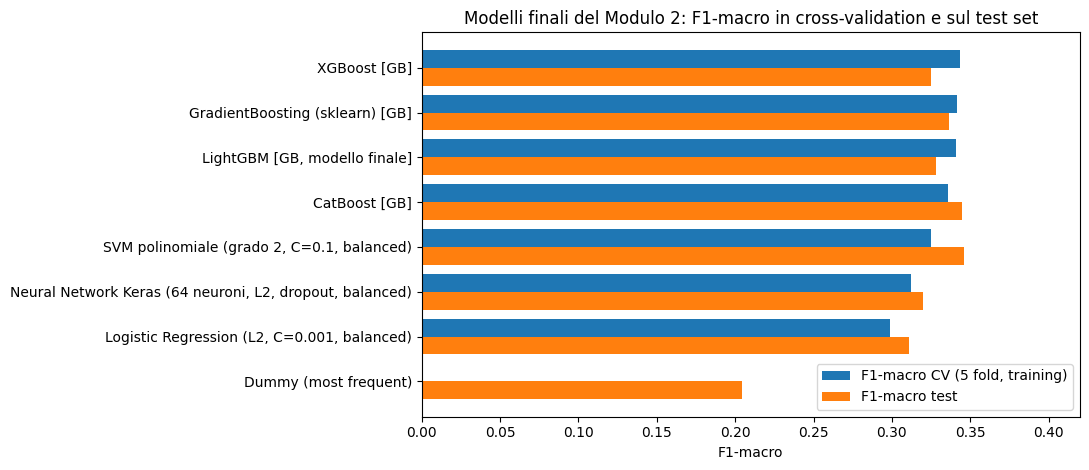

,modello,f1_macro_cv,f1_macro,balanced_acc,roc_auc,accuracy,f1_macro_cv_rip
0,XGBoost [GB],0.343,0.325,0.338,0.678,0.566,0.331
1,GradientBoosting (sklearn) [GB],0.342,0.337,0.383,0.698,0.518,0.337
2,"LightGBM [GB, modello finale]",0.341,0.328,0.344,0.701,0.569,0.340
3,CatBoost [GB],0.336,0.345,0.387,0.705,0.544,0.334
4,"SVM polinomiale (grado 2, C=0.1, balanced)",0.325,0.346,0.366,0.689,0.573,NaN
5,"Neural Network Keras (64 neuroni, L2, dropout, balanced)",0.312,0.320,0.379,0.674,0.496,NaN
6,"Logistic Regression (L2, C=0.001, balanced)",0.299,0.311,0.391,0.679,0.505,NaN
7,Dummy (most frequent),NaN,0.204,0.250,0.500,0.690,NaN


In [20]:
# Modelli finali degli altri notebook (stesso test set: split 80/20, random_state=42)
altri = pd.DataFrame([
    {'modello': 'Logistic Regression (L2, C=0.001, balanced)', 'f1_macro_cv': 0.299, 'f1_macro': 0.311,
     'balanced_acc': 0.391, 'roc_auc': 0.679, 'accuracy': 0.505},
    {'modello': 'Neural Network Keras (64 neuroni, L2, dropout, balanced)', 'f1_macro_cv': 0.312, 'f1_macro': 0.320,
     'balanced_acc': 0.379, 'roc_auc': 0.674, 'accuracy': 0.496},
    {'modello': 'SVM polinomiale (grado 2, C=0.1, balanced)', 'f1_macro_cv': 0.325, 'f1_macro': 0.346,
     'balanced_acc': 0.366, 'roc_auc': 0.689, 'accuracy': 0.573},
])
colonne = ['modello', 'f1_macro_cv', 'f1_macro', 'balanced_acc', 'roc_auc', 'accuracy']
gb = risultati_test[colonne + ['f1_macro_cv_rip']].copy()
gb['modello'] = gb['modello'].map(lambda n: n if n.startswith('Dummy') else
                                  n + (' [GB, modello finale]' if n == NOME_FINALE else ' [GB]'))
confronto = pd.concat([gb.iloc[:1], altri[colonne], gb.iloc[1:]], ignore_index=True)
confronto = confronto.sort_values('f1_macro_cv', ascending=False, na_position='last').reset_index(drop=True)

c = confronto.iloc[::-1]
yy = np.arange(len(c))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(yy + 0.2, c['f1_macro_cv'].fillna(0), 0.4, color='tab:blue', label='F1-macro CV (5 fold, training)')
ax.barh(yy - 0.2, c['f1_macro'], 0.4, color='tab:orange', label='F1-macro test')
ax.set_yticks(yy); ax.set_yticklabels(c['modello']); ax.set_xlabel('F1-macro'); ax.set_xlim(0, 0.42)
ax.set_title('Modelli finali del Modulo 2: F1-macro in cross-validation e sul test set'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

pd.set_option('display.max_colwidth', 70)
confronto.round(3)

**Commento.**
- **In cross-validation** i modelli di Gradient Boosting hanno la F1-macro più alta del Modulo 2: 0.336-0.343 nella
  ricerca (0.331-0.340 nella CV ripetuta) contro 0.325 dell'SVM polinomiale, 0.312 della rete neurale e 0.299 della
  Logistic Regression. Il vantaggio sull'SVM (circa 0.015) è però dello stesso ordine della deviazione standard fra i
  fold (0.008-0.023).
- **Sul test** il modello finale (LightGBM) ha F1-macro 0.328: sotto l'SVM (0.346) e sopra la rete neurale (0.320) e la
  Logistic Regression (0.311). L'ordine fra Gradient Boosting e SVM è quindi opposto in CV e sul test, con distanze di
  0.016-0.018 in entrambi i casi: i due modelli non sono distinguibili.
- **ROC AUC**: LightGBM 0.701 contro 0.689 (SVM calibrata), 0.679 (LR) e 0.674 (NN); differenze piccole.
- **Balanced accuracy**: LightGBM 0.344, inferiore a LR (0.391), NN (0.379) e SVM (0.366). Questi tre modelli, con pesi
  bilanciati, distribuiscono di più le predizioni sulle classi minoritarie; il modello finale del Gradient Boosting,
  adattandosi di più al training, resta più vicino alla classe 0 (accuracy 0.569 contro 0.505 della LR).
- **Classe 3**: è la differenza di risultato più visibile. Il modello finale del Gradient Boosting non individua nessuno
  dei 18 casi del test, mentre la SVM polinomiale ne trova 2, la rete neurale 4 e la Logistic Regression 7 (recall 0.111,
  0.222 e 0.389). Per tutti e tre la precision sulla classe 3 è però intorno al 3% e la F1 è circa 0.05: individuano
  qualche caso al prezzo di molti falsi positivi.
- **Nessun salto di qualità**: un modello non lineare e molto flessibile, capace di arrivare a F1-macro 1.0 sul
  training, in validazione si ferma dove si fermano gli altri (0.31-0.35). È la conferma più forte che il limite è nei
  dati e non nel classificatore.

**📌 Report**
- Tabella di confronto finale e grafico a barre (F1-macro in CV e sul test per tutti i modelli del Modulo 2).
- Usare formulazioni prudenti: "il Gradient Boosting ha la F1-macro in CV più alta", "sul test è fra l'SVM e la rete
  neurale, con differenze entro la variabilità fra i fold".
- Citare nel confronto la classe 3: 0 casi su 18 per LightGBM contro 2 (SVM), 4 (NN) e 7 (LR).

In [21]:
print(f'Tempo totale di esecuzione del notebook: {(time.time() - T_INIZIO) / 60:.1f} minuti')

Tempo totale di esecuzione del notebook: 8.4 minuti


## 11. Sintesi per il report

### Tabella riassuntiva (test set comune, split 80/20, `random_state=42`)

| Modello | F1-macro CV (5 fold) | F1-macro CV ripetuta (3×5) | F1-macro test | Bal. acc. | ROC AUC | Accuracy | F1 classe 0 / 1 / 2 / 3 |
|---|---|---|---|---|---|---|---|
| Dummy (most frequent) | 0.204 | – | 0.204 | 0.250 | 0.500 | 0.690 | 0.816 / 0 / 0 / 0 |
| **LightGBM (modello finale)** | 0.341 | **0.340** | **0.328** | 0.344 | 0.701 | 0.569 | 0.732 / 0.294 / 0.287 / 0.000 |
| GradientBoosting (sklearn) | 0.342 | 0.337 | 0.337 | 0.383 | 0.698 | 0.518 | 0.671 / 0.307 / 0.328 / 0.040 |
| CatBoost | 0.336 | 0.334 | 0.345 | 0.387 | 0.705 | 0.544 | 0.703 / 0.269 / 0.346 / 0.061 |
| XGBoost | 0.343 | 0.331 | 0.325 | 0.338 | 0.678 | 0.566 | 0.728 / 0.276 / 0.296 / 0.000 |
| SVM polinomiale (altro notebook) | 0.325 | – | 0.346 | 0.366 | 0.689 | 0.573 | – |
| Neural Network (altro notebook) | 0.312 | – | 0.320 | 0.379 | 0.674 | 0.496 | – |
| Logistic Regression (altro notebook) | 0.299 | – | 0.311 | 0.391 | 0.679 | 0.505 | – |

**Modello finale: LightGBM** con `class_weight='balanced'`, `n_estimators=100`, `learning_rate=0.1`, `num_leaves=16`,
`max_depth=6`, `min_child_samples=10`, `colsample_bytree=1.0`, `subsample=1.0`, `reg_lambda=0`.

### Messaggi chiave

1. **I pesi di classe sono decisivi anche nel Gradient Boosting.** Con i default: F1-macro CV 0.28-0.30 senza pesi,
   0.32-0.33 con pesi `balanced`. Nel tuning nessuna delle 50 configurazioni senza pesi supera 0.314, contro 0.336-0.343
   delle migliori con i pesi.
2. **Overfitting fortissimo, ma poco dannoso.** Con i parametri di default i modelli arrivano a F1-macro 0.97-1.00 sul
   training e 0.32-0.33 in validazione. Con il tuning il training dei modelli migliori scende a 0.54-0.83 e la
   validazione sale solo a 0.34. Oltre F1 ≈ 0.6 sul training non si guadagna più nulla.
3. **Numero di alberi e learning rate vanno scelti insieme.** Con lr 0.05-0.1 la F1-macro cresce fino a 300-600 alberi e
   resta stabile; con lr 0.3 il massimo è a 200 alberi e poi cala; con lr 1.0 (il valore degli esempi di laboratorio) il
   modello peggiora dopo 30 alberi; con lr 0.01 600 alberi non bastano.
4. **L'early stopping sulla log-loss si ferma troppo presto.** La log-loss di validation (pesata) è minima dopo 17
   alberi con lr 0.1, dove la F1-macro è circa 0.30; continuando si arriva a 0.34. Il minimo (≈1.33) è vicino a
   ln 4 ≈ 1.386: le probabilità sono poco informative.
5. **Le quattro librerie sono equivalenti** (0.331-0.340 nella CV ripetuta, ROC AUC 0.678-0.705 sul test). XGBoost e
   LightGBM sono nettamente più veloci del Gradient Boosting classico e di CatBoost (con i default 2-5 s contro 14-18 s
   per la CV), ma non più accurati su 6768 righe.
6. **Il migliore di una ricerca è una stima ottimistica.** XGBoost era primo nella ricerca (0.343) e ultimo nella CV
   ripetuta (0.331); gli altri tre modelli confermano i loro punteggi (differenze ≤ 0.005). Sul test i quattro modelli
   variano fra 0.325 e 0.345, con un ordine ancora diverso: un singolo test set con 18 esempi nella classe 3 non basta
   per ordinare modelli equivalenti.
7. **Classe 3 mai individuata dal modello finale** (0 su 18; F1 = 0 anche per XGBoost, 0.040 per GradientBoosting e
   0.061 per CatBoost). SVM, NN e LR ne individuano 2, 4 e 7, ma con precision intorno al 3%. La classe 1 ha la ROC AUC
   più bassa (0.640) e gli errori sono soprattutto fra classi adiacenti.
8. **Accuracy e F1-macro in direzioni opposte**: LightGBM e XGBoost hanno l'accuracy più alta (0.57) e la F1-macro più
   bassa (0.328 e 0.325); CatBoost e GradientBoosting hanno accuracy più bassa (0.54 e 0.52) e F1-macro più alta
   (0.345 e 0.337).
9. **Feature importance diffuse e stabili**: le prime 10 feature coprono meno della metà dell'importanza (37-47%),
   l'ordine è molto simile nelle quattro librerie (Spearman 0.87-0.97). In testa misure fisiche, CGAS e punteggi del
   sonno (SDS).
10. **Confronto con gli altri classificatori**: F1-macro in CV più alta del Modulo 2 (0.341 contro 0.325 dell'SVM), ma
    sul test sotto l'SVM (0.328 contro 0.346) e sopra NN e LR (0.320 e 0.311); balanced accuracy più bassa di LR, NN e
    SVM. Le distanze sono entro la variabilità fra i fold. Il modello più flessibile non supera il limite di 0.31-0.35:
    **il limite è nei dati**.

### Grafici e tabelle da inserire nel report

- **Tabelle**: baseline con/senza pesi (sez. 4); riepilogo per learning rate (sez. 5); migliori configurazioni e
  iperparametri provati per libreria (sez. 6); riepilogo ricerca + CV ripetuta (sez. 7.1); risultati sul test (sez. 8);
  confronto finale (sez. 10).
- **Grafici**: curve log-loss / F1-macro al crescere del numero di alberi per learning rate (sez. 5); F1-macro CV per
  pesi di classe e training-vs-CV (sez. 7); confusion matrix normalizzata, ROC e Precision-Recall del modello finale
  (sez. 8); feature importance (sez. 9); barre di confronto fra i modelli del Modulo 2 (sez. 10).

### Differenze di impostazione rispetto a LR, SVM e NN (da dichiarare nel report)

- **Scelta del modello finale**: CV ripetuta (3×5) sui quattro finalisti, mentre gli altri notebook scelgono sul
  `best_score_` della 5-fold. Con quel criterio il modello finale sarebbe stato XGBoost (F1-macro CV 0.343, test 0.325)
  invece di LightGBM (CV 0.341, test 0.328): i numeri del confronto cambierebbero di pochi millesimi. La colonna usata
  nel confronto è quella a 5 fold, quindi è omogenea con gli altri notebook.
- **Classe 3**: mai individuata dal modello finale (0 su 18), mentre SVM e NN ne trovano 2 e 4.
- I pesi di classe provati sono gli stessi degli altri notebook (`None` e `balanced`).

### Limiti e note

- Ricerche ridotte per CatBoost e `GradientBoostingClassifier` (12 configurazioni, di cui solo 5 con i pesi) per restare
  nei tempi.
- CatBoost è usato con le variabili categoriche già in one-hot (stesso preprocessing degli altri modelli), quindi senza
  il suo encoding specifico; lo stesso vale per la gestione nativa delle categoriche di LightGBM.
- Explainable Boosting Machine (ultima parte delle slide) non è inclusa: rientra nella parte di explainability.
- I risultati sono riproducibili sulla stessa macchina (ogni modello usa 1 thread e un seed fissato); fra computer o
  versioni diverse delle librerie possono esserci piccole differenze, che possono far selezionare una configurazione
  diversa.
- Versioni usate per questi risultati: scikit-learn 1.7.2, xgboost 3.4.1, lightgbm 4.7.0, catboost 1.2.10; tempo totale
  di esecuzione 8.4 minuti.